# 06 - bts-pivot: triage a weekend of cyber logs with auto-fitted pivots

One call turns 50k auth, firewall and proxy events into the pivot table that best fits the screen; the same object toggles to a histogram, slices, scores spikes and novelties, walks Markov chains and answers an MCP agent, all without a model call.

| | |
| --- | --- |
| **Package** | `bts-pivot` 0.21.2 on PyPI, pure pandas/numpy core, optional `pyarrow`, `duckdb`, `scikit-learn`, `mcp`, `ipywidgets` |
| **Does** | auto-fits a pivot layout to any table, toggles pivot/histogram, slices, bins, clusters, detects spikes and new entities, builds Markov chains and HMM regimes, pages Parquet/DuckDB sources that exceed RAM, exposes 13 MCP tools |
| **Use it when** | you have a log file and a question like "what is unusual this weekend" and want computed, checkable numbers before anyone (human or LLM) starts reasoning |

## What you will build

| Section | What you do | Time |
| --- | --- | --- |
| Setup | install, build a 50k-row weekend of logs for a faker company with four planted anomalies | 2 min |
| Part 1 - Quick start | `bp.fit(df)`, toggle to a histogram and back, stack two slices, read the suggestion menu | 5 min |
| Part 2 - Working session | a SOC analyst's triage: source IP pivots, drill levels, bin rules, `spikes()`, `novel()`, `explain()`, chains and regimes, clustering, `insights()`, HTML export, paging a 500k-row Parquet file, DuckDB, the CLI, the Jupyter explorer, the MCP server end to end | 20 min |
| Part 3 - Solving a critical problem | the credential-stuffing run Sunday 03:00 that the dashboard totals never showed: hour x status pivot, toggle, spikes and novelty on user agent, the fail-fail-success Markov chain, slice to the IPs, the HTML for the incident ticket, before/after | 10 min |
| Part 4 - Deep dive | how the fit scores a layout, how bins and time buckets are chosen, how spikes and novelties are scored, the HMM behind `regimes()`, the DuckDB pushdown, limitations | 15 min |
| Benchmark | fit and table time against plain pandas on the same 50k rows and a 500k-row Parquet file (paged, DuckDB), recall of the five planted anomalies with false positives, memory for paging, prompt size; a scorecard built from the run | 5 min |

## Setup

The `plot`, `parquet`, `duckdb`, `cluster` and `mcp` extras are used below; `jupyter` adds the interactive explorer, which this notebook only snapshots to static HTML.

In [1]:
import subprocess, sys
r = subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "--break-system-packages",
                    "bts-pivot[plot,parquet,duckdb,cluster,mcp,jupyter]", "faker"], text=True, capture_output=True)
print("pip exit code:", r.returncode)

pip exit code: 0


In [2]:
import os, json, random, time, textwrap
import numpy as np
import pandas as pd
from faker import Faker
from IPython.display import HTML, Markdown, display

import bts_pivot as bp

pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 90)
print("bts-pivot", bp.__version__, "| pandas", pd.__version__)

bts-pivot 0.21.2 | pandas 3.0.5


In [3]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Circle, FancyArrowPatch

INK, PAPER, LINE = "#1f2328", "#ffffff", "#d0d7de"
FILL = {"step": "#eaeef2", "accent": "#ddf4ff", "warn": "#fff1e5", "good": "#dafbe1"}

def canvas(w=11, h=3.2):
    fig, ax = plt.subplots(figsize=(w, h), dpi=120)
    ax.set_xlim(0, w); ax.set_ylim(0, h); ax.axis("off")
    fig.patch.set_facecolor(PAPER)
    return fig, ax

def box(ax, x, y, w, h, text, kind="step", fs=9.5):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.12",
                                fc=FILL[kind], ec=LINE, lw=1.2))
    ax.text(x + w/2, y + h/2, text, ha="center", va="center", fontsize=fs, color=INK,
            family="DejaVu Sans", linespacing=1.4)

def dot(ax, x, y, r, text, kind="accent", fs=9.5):
    ax.add_patch(Circle((x, y), r, fc=FILL[kind], ec=LINE, lw=1.2))
    ax.text(x, y, text, ha="center", va="center", fontsize=fs, color=INK, family="DejaVu Sans")

def arrow(ax, x1, y1, x2, y2, label=None, fs=8.5):
    ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle="-|>", mutation_scale=12,
                                 color=INK, lw=1.1, shrinkA=2, shrinkB=2))
    if label:
        ax.text((x1+x2)/2, (y1+y2)/2 + 0.16, label, ha="center", va="bottom", fontsize=fs,
                color="#57606a", family="DejaVu Sans", zorder=5,
                bbox=dict(fc=PAPER, ec="none", pad=1.5))

def note(ax, x, y, text, fs=9, ha="left"):
    ax.text(x, y, text, ha=ha, va="center", fontsize=fs, color="#57606a", family="DejaVu Sans",
            zorder=5, bbox=dict(fc=PAPER, ec="none", pad=1.5))

### The data: one weekend at a faker company

Friday 18:00 to Monday 08:00, three log sources merged into one frame (auth, firewall, proxy), 420 internal workstations in fourteen `/24` subnets, 180 users, 30 hosts. Four anomalies are planted so the rest of the notebook can be read as a detection exercise:

| Planted anomaly | Where | Rows | What should surface it |
| --- | --- | --- | --- |
| brute force | one external IP, Saturday 03:10-03:40, `login` with status 401 against the VPN hosts, rotating usernames | 2,500 | `spikes()` on a `src_ip` pivot, `explain()`, `novel()` |
| rare country | 40 proxy downloads from `KP`, Sunday afternoon | 40 | `novel("country", ...)`, `anomalies()` |
| off-hours user | one user pulling large downloads from the `db-*` hosts Sunday 02:00-04:00 | 900 | the auto-fit itself, `spikes()` on a `user` pivot |
| novel user agent | `python-requests/2.31.0` appears for the first time Sunday 19:00 from two workstations | 300 | `novel("user_agent", ...)`, `insights()` |

A fifth anomaly is planted too and deliberately not listed here: Part 3 is about finding it.

In [4]:
Faker.seed(7); random.seed(7)
fake = Faker()
rng = np.random.default_rng(7)

COMPANY, DOMAIN = fake.company(), fake.domain_name()
ANALYST = fake.name()
T0, T1 = pd.Timestamp("2026-10-30 18:00"), pd.Timestamp("2026-11-02 08:00")   # Friday evening to Monday morning
SPAN = (T1 - T0).total_seconds()

users = sorted({fake.user_name() for _ in range(200)})[:180]
hosts = [f"{k}-{i:02d}.{DOMAIN}" for k in ("vpn", "web", "jump", "db", "mail") for i in range(1, 7)]
subnets = [f"10.{a}.{b}" for a in (1, 2, 3) for b in rng.choice(range(32), 5, replace=False)][:14]
ip_pool = np.array([f"{s}.{h}" for s in subnets for h in rng.choice(range(1, 250), 30, replace=False)])
countries, c_w = ["US", "GB", "DE", "NL", "CA", "IN", "BR", "FR"], [0.55, 0.1, 0.08, 0.05, 0.08, 0.07, 0.04, 0.03]
agents = [fake.user_agent() for _ in range(12)]
ua_w = np.array([30, 20, 15, 10, 8, 5, 4, 3, 2, 1, 1, 1]) / 100

# baseline traffic: a weekend lull with a mild daytime bump, rows thinned at night
N = 64_000
t = rng.uniform(0, SPAN, N)
hour = (T0 + pd.to_timedelta(t, unit="s")).hour
t = t[rng.random(N) < np.where((hour >= 8) & (hour <= 20), 1.0, 0.45)]
n = len(t)
user_w = np.arange(1, len(users) + 1) ** -0.9; user_w /= user_w.sum()
base = pd.DataFrame({
    "timestamp": T0 + pd.to_timedelta(t, unit="s"),
    "source": rng.choice(["auth", "firewall", "proxy"], n, p=[0.35, 0.4, 0.25]),
    "src_ip": rng.choice(ip_pool, n),
    "user": rng.choice(users, n, p=user_w),
    "host": rng.choice(hosts, n),
    "action": rng.choice(["login", "logout", "allow", "deny", "download", "upload"], n, p=[0.25, 0.1, 0.35, 0.08, 0.15, 0.07]),
    "status": rng.choice([200, 302, 401, 403, 404, 500], n, p=[0.7, 0.1, 0.08, 0.05, 0.05, 0.02]),
    "bytes": np.exp(rng.normal(7.5, 2.0, n)).astype(int),
    "country": rng.choice(countries, n, p=c_w),
    "user_agent": rng.choice(agents, n, p=ua_w),
})
base.loc[base.action == "deny", "status"] = 403
base.loc[(base.action == "login") & (rng.random(n) < 0.08), "status"] = 401

# the four planted anomalies
BRUTE_IP, RARE_COUNTRY, OFFHOURS_USER, NOVEL_UA = "185.220.101.47", "KP", users[57], "python-requests/2.31.0"
def burst(start, seconds, m, **fixed):
    d = {"timestamp": pd.Timestamp(start) + pd.to_timedelta(rng.uniform(0, seconds, m), unit="s")}
    d.update({k: (v(m) if callable(v) else v) for k, v in fixed.items()})
    return pd.DataFrame(d)

brute = burst("2026-10-31 03:10", 1800, 2500, source="auth", src_ip=BRUTE_IP, user=lambda m: rng.choice(users, m),
              host=lambda m: rng.choice(hosts[:6], m), action="login", status=401,
              bytes=lambda m: rng.integers(300, 600, m), country="RU", user_agent=lambda m: rng.choice(agents[:3], m))
rare = burst("2026-11-01 14:00", 7200, 40, source="proxy", src_ip="175.45.176.9", user=lambda m: rng.choice(users[:20], m),
             host=lambda m: rng.choice(hosts[6:12], m), action="download", status=200,
             bytes=lambda m: np.exp(rng.normal(11, 0.5, m)).astype(int), country=RARE_COUNTRY, user_agent=agents[0])
offhours = burst("2026-11-01 02:00", 7200, 900, source="proxy", src_ip=ip_pool[77], user=OFFHOURS_USER,
                 host=lambda m: rng.choice(hosts[18:24], m), action="download", status=200,
                 bytes=lambda m: np.exp(rng.normal(12, 0.8, m)).astype(int), country="US", user_agent=agents[1])
novel_ua = burst("2026-11-01 19:00", 10800, 300, source="proxy", src_ip=lambda m: rng.choice(ip_pool[300:302], m),
                 user=lambda m: rng.choice(users[:3], m), host=lambda m: rng.choice(hosts[6:12], m),
                 action=lambda m: rng.choice(["allow", "download"], m), status=200,
                 bytes=lambda m: rng.integers(2000, 9000, m), country="US", user_agent=NOVEL_UA)

# a fifth, quiet one for Part 3: low-and-slow credential stuffing, Sunday 03:00-04:00
STUFF_UA, STUFF_IPS = "okhttp/4.9.3", [f"45.134.26.{k}" for k in (17, 18, 21, 23, 29, 31)]
targets = rng.choice(users, 60, replace=False)
stuff_rows = []
for i, u in enumerate(targets):
    t0 = pd.Timestamp("2026-11-01 03:00") + pd.to_timedelta(rng.uniform(0, 3600), unit="s")
    outcome = ["login_fail", "login_fail", "login_ok" if i < 45 else "login_fail"]   # 45 of 60 passwords were in the dump
    for k, ev in enumerate(outcome):
        stuff_rows.append({"timestamp": t0 + pd.Timedelta(seconds=5 * k + rng.uniform(0, 2)), "source": "auth",
                           "src_ip": STUFF_IPS[i % 6], "user": u, "host": hosts[i % 6], "action": "login",
                           "status": 200 if ev == "login_ok" else 401, "bytes": int(rng.integers(400, 700)),
                           "country": "US", "user_agent": STUFF_UA})
stuffing = pd.DataFrame(stuff_rows)

logs = pd.concat([base, brute, rare, offhours, novel_ua, stuffing]).sort_values("timestamp").reset_index(drop=True)
logs["event"] = np.where(logs.action == "login", np.where(logs.status == 401, "login_fail", "login_ok"), logs.action)
print(f"{COMPANY} ({DOMAIN}) - analyst on call: {ANALYST}")
print(f"{len(logs):,} rows, {logs.timestamp.min()} -> {logs.timestamp.max()}; off-hours user = {OFFHOURS_USER}")
logs.head()

Gould-Foster (jones.com) - analyst on call: Anthony Romero
49,167 rows, 2026-10-30 18:00:04.820201491 -> 2026-11-02 07:59:45.013368925; off-hours user = georgemartinez


,timestamp,source,src_ip,user,host,action,status,bytes,country,user_agent,event
0,2026-10-30 18:00:04.820201491,firewall,10.1.31.161,simonkyle,mail-06.jones.com,download,200,12255,US,"Mozilla/5.0 (iPhone; CPU iPhone OS 17_3 like Mac OS X) AppleWebKit/534.1 (KHTML, like ...",download
1,2026-10-30 18:00:06.380121685,auth,10.1.31.126,idunn,web-04.jones.com,allow,200,40,CA,Mozilla/5.0 (compatible; MSIE 6.0; Windows NT 6.1; Trident/5.0),allow
2,2026-10-30 18:00:08.414127436,auth,10.2.26.119,adamsandre,jump-03.jones.com,logout,200,6100,GB,"Mozilla/5.0 (iPhone; CPU iPhone OS 5_1_1 like Mac OS X) AppleWebKit/536.2 (KHTML, like...",logout
3,2026-10-30 18:00:19.213066461,firewall,10.2.28.204,andrew75,vpn-06.jones.com,login,404,61,CA,"Mozilla/5.0 (iPhone; CPU iPhone OS 5_1_1 like Mac OS X) AppleWebKit/536.2 (KHTML, like...",login_ok
4,2026-10-30 18:00:19.273114805,firewall,10.2.0.155,rmcintosh,web-03.jones.com,logout,200,1708,US,"Mozilla/5.0 (iPhone; CPU iPhone OS 11_4_1 like Mac OS X) AppleWebKit/533.0 (KHTML, lik...",logout


`event` is `action` with `login` split by outcome, so a chain of `login_fail` reads as one state. The frame is a plain pandas DataFrame; nothing about it is bts-pivot specific yet.

---

## Part 1 - Quick start

`bp.fit()` profiles every column, picks a measure and searches row/column layouts for the one that fits a 40 x 12 box best. No arguments, no schema.

In [5]:
v = bp.fit(logs)
print(v.describe(), "| confidence:", v.confidence)
v

sum(bytes) by host x timestamp (6 h) | confidence: medium


pivot · sum(bytes) by host x timestamp (6 h) · 49,167 rows
timestamp (6 h)   2026-10-30 18:00 2026-10-31 00:00 2026-10-31 06:00 2026-10-31 12:00  \
host                                                                                    
vpn-05.jones.com           922,175        1,520,626        2,174,849        2,801,747   
vpn-06.jones.com         1,245,722          940,210        1,268,144        3,562,844   
vpn-02.jones.com         1,205,632        1,045,784        1,099,104        3,705,563   
vpn-01.jones.com         1,309,718        3,540,503        2,104,744        2,845,759   
vpn-03.jones.com         1,580,348        1,233,287        1,517,784        2,231,023   
vpn-04.jones.com         3,064,527        1,088,515        1,990,341        4,010,087   
db-04.jones.com          1,494,821          733,516        2,797,084        2,810,978   
db-06.jones.com          1,711,265        1,521,939        1,515,509        3,036,883   
db-05.jones.com          1,798,929          445,929        1,746,886        1,595,624   
db-03.jones.com          1,543,360        1,928,685        4,398,525        1,629,990   
db-02.jones.com          1,916,421        3,030,100        2,041,670        5,043,963   
db-01.jones.com          1,580,744          866,258        3,875,339        1,827,757   
web-02.jones.com         1,830,060        1,990,685        1,432,262        3,071,607   
web-03.jones.com         3,204,560        1,322,279        2,180,844        1,785,170   
jump-04.jones.com        1,794,807        1,014,552        1,554,656        6,136,975   
web-05.jones.com         1,387,636        1,116,377        2,814,599        2,434,631   
web-04.jones.com         1,655,115        2,787,943        2,834,876        1,353,553   
web-01.jones.com         1,978,720          692,658        3,611,469        4,460,434   
mail-05.jones.com        2,402,700        4,132,300        3,239,703        2,124,754   
web-06.jones.com         1,948,004          853,135        1,567,903        3,921,401   
mail-01.jones.com        1,624,262        1,020,010        2,691,943        2,157,773   
mail-03.jones.com        1,869,180        1,296,791        1,966,541        3,322,253   
jump-06.jones.com        1,860,026          823,635        2,110,217        2,802,563   
jump-02.jones.com        1,590,329          640,087        1,635,763        4,374,645   
jump-03.jones.com        1,089,858        1,597,577        2,070,127        1,734,247   
jump-01.jones.com        1,488,797        1,130,874        1,020,279        2,266,237   
mail-02.jones.com        2,018,694        2,492,591        3,203,928        2,654,867   
mail-06.jones.com        1,334,330          706,446        1,519,228        2,192,176   
jump-05.jones.com        1,728,121        1,277,755        2,718,585        2,614,444   
mail-04.jones.com        1,627,829          826,980        2,088,990        1,870,584   

timestamp (6 h)   2026-10-31 18:00 2026-11-01 00:00 2026-11-01 06:00 2026-11-01 12:00  \
host                                                                                    
vpn-05.jones.com         3,322,209        8,497,135        3,128,040        2,714,725   
vpn-06.jones.com         1,353,301          858,103        1,665,593        2,335,690   
vpn-02.jones.com         2,467,673        3,192,343        3,568,980        1,932,063   
vpn-01.jones.com         3,350,740          859,852        4,905,943        2,932,136   
vpn-03.jones.com         2,166,931        1,399,839        2,125,950        3,002,863   
vpn-04.jones.com         2,320,662          701,091        1,502,409        3,026,549   
db-04.jones.com          1,738,682       33,167,824        1,360,807        3,957,641   
db-06.jones.com          2,448,377       32,182,423        1,828,749        2,513,933   
db-05.jones.com          1,818,048       33,656,083        2,468,534        5,146,065   
db-03.jones.com            721,960       35,607,284        1,356,635        1,412,728   
db-02.jones.com         

The fit chose `sum(bytes)` as the measure because `bytes` looks additive, put the 30 hosts down the side (entities go on rows) and 6-hour buckets across the top (11 columns fit the 12-column budget). Read the heat: the six `db-*` rows in the `2026-11-01 00:00` column are tens of millions of bytes against hundreds of thousands everywhere else. **That is the off-hours download spike, visible before any detection code ran.**

`confidence` is `medium`: at least one runner-up scored close enough to be worth a look. The suggestion menu shows them, best first.

In [6]:
for i, layout in enumerate(v.suggest(5), 1):
    print(i, layout.describe())

1 sum(bytes) by host x timestamp (6 h)
2 sum(bytes) by host x action > timestamp (week)
3 sum(bytes) by host x action
4 sum(bytes) by host x event
5 sum(bytes) by user (top 39) x timestamp (6 h)


`toggle()` flips the same layout to a histogram: rows become bins, columns become series. Toggle again and the pivot is back.

In [7]:
h = v.toggle()
print(h.describe(), "| is_hist:", h.is_hist)
print("round trip:", h.toggle().describe())
h

sum(bytes) by host x timestamp (6 h) | is_hist: True


round trip: sum(bytes) by host x timestamp (6 h)


hist · sum(bytes) by host x timestamp (6 h) · 49,167 rows
host               2026-10-30 1  2026-10-31 0  2026-10-31 0  2026-10-31 1  2026-10-31 1  2026-11-01 0  2026-11-01 0  2026-11-01 1  2026-11-01 1  2026-11-02 0  2026-11-02 0
vpn-05.jones.com   ▏       922K  ▎      1.52M  ▍      2.17M  ▌       2.8M  ▌      3.32M  █▍      8.5M  ▌      3.13M  ▌      2.71M  ▎      1.26M  ▍      1.92M  ▏       211K
vpn-06.jones.com   ▎      1.25M  ▏       940K  ▎      1.27M  ▋      3.56M  ▎      1.35M  ▏       858K  ▎      1.67M  ▍      2.34M  ▎      1.66M  ▎      1.75M  ▏       290K
vpn-02.jones.com   ▎      1.21M  ▏      1.05M  ▏       1.1M  ▋      3.71M  ▍      2.47M  ▌      3.19M  ▋      3.57M  ▍      1.93M  ▏      1.07M  ▎      1.22M  ▏       166K
vpn-01.jones.com   ▎      1.31M  ▋      3.54M  ▍       2.1M  ▌      2.85M  ▋      3.35M  ▏       860K  ▉      4.91M  ▌      2.93M  ▍      1.94M  ▏       695K  ▏       344K
vpn-03.jones.com   ▎      1.58M  ▎      1.23M  ▎      1.52M  ▍      2.23M  ▍      2.17M  ▎       1.4M  ▍      2.13M  ▌         3M  ▎      1.73M  ▎      1.41M  ▏       101K
vpn-04.jones.com   ▌      3.06M  ▏      1.09M  ▍      1.99M  ▋      4.01M  ▍      2.32M  ▏       701K  ▎       1.5M  ▌      3.03M  ▌      2.68M  ▎      1.53M  ▏       282K
db-04.jones.com    ▎      1.49M  ▏       734K  ▌       2.8M  ▌      2.81M  ▎      1.74M  █████▋ 33.2M  ▎      1.36M  ▋      3.96M  ▎      1.49M  ▏       948K  ▏       633K
db-06.jones.com    ▎      1.71M  ▎      1.52M  ▎      1.52M  ▌      3.04M  ▍      2.45M  █████▍ 32.2M  ▎      1.83M  ▍      2.51M  ▌      3.32M  ▏       775K  ▏       372K
db-05.jones.com    ▎       1.8M  ▏       446K  ▎      1.75M  ▎       1.6M  ▎      1.82M  █████▋ 33.7M  ▍      2.47M  ▉      5.15M  ▌      2.96M  ▎      1.44M  ▏       322K
db-03.jones.com    ▎      1.54M  ▍      1.93M  ▊       4.4M  ▎      1.63M  ▏       722K  ██████ 35.6M  ▎      1.36M  ▎      1.41M  ▎      1.45M  ▏       337K  ▏       553K
db-02.jones.com    ▍      1.92M  ▌      3.03M  ▍      2.04M  ▉      5.04M  ▍      2.36M  █████▊   34M  ▍      2.23M  ▎      1.67M  ▍      2.28M  ▏       885K  ▏       261K
db-01.jones.com    ▎      1.58M  ▏       866K  ▋      3.88M  ▎      1.83M  ▎      1.78M  █████▊ 33.9M  ▍      2.35M  ▌      2.87M  ▎       1.5M  ▎      1.62M  ▏      69.5K
web-02.jones.com   ▎      1.83M  ▍      1.99M  ▎      1.43M  ▌      3.07M  ▎      1.82M  ▏       981K  ▍      2.33M  ▋      3.64M  ▍       2.1M  ▌      2.66M  ▏       355K
web-03.jones.com   ▌       3.2M  ▎      1.32M  ▍      2.18M  ▎      1.79M  ▎      1.61M  ▏       924K  ▌      3.15M  ▌      2.76M  ▍      1.95M  ▎      1.44M  ▏       380K
jump-04.jones.com  ▎      1.79M  ▏      1.01M  ▎      1.55M  █      6.14M  ▎      1.68M  ▎      1.16M  ▎      1.78M  ▋      3.86M  ▎      1.27M  ▏       695K  ▏       120K
web-05.jones.com   ▎      1.39M  ▎      1.12M  ▌      2.81M  ▍      2.43M  ▍      2.28M  ▏      1.03M  ▎      1.59M  ▌      2.76M  ▍      2.43M  ▏       841K  ▏       260K
web-04.jones.com   ▎      1.66M  ▌      2.79M  ▌      2.83M  ▎      1.35M  ▌      3.15M  ▏       864K  ▎      1.67M  ▍      2.18M  ▌      2.72M  ▏       914K  ▏       270K
web-01.jones.com   ▍      1.98M  ▏       693K  ▋      3.61M  ▊      4.46M  ▌      2.74M  ▎      1.33M  ▍      2.19M  ▌      2.68M  ▌      2.92M  ▌      2.76M  ▏      61.9K
mail-05.jones.com  ▍       2.4M  ▊      4.13M  ▌      3.24M  ▍      2.12M  ▎      1.35M  ▏       714K  ▍      1.86M  ▍      2.22M  ▎      1.48M  ▏       806K  ▏       208K
web-06.jones.com   ▍      1.95M  ▏       853K  ▎      1.57M  ▋      3.92M  ▎      1.82M  ▍      2.45M  ▎      1.54M  ▌       2.8M  ▎      1.21M  ▎      1.17M  ▏       313K
mail-01.jones.com  ▎      1.62M  ▏      1.02M  ▌      2.69M  ▍      2.16M  ▎      1.27M  ▏       952K  ▍      2.22M  ▍      1.92M  ▎      1.79M  ▏       933K  ▏      64.2K
mail-03.jones.com  ▍      1.87M  ▎       1.3M  ▍      1.97M  ▌      3.32M  ▎      1.15M  ▎       1.3M  ▋       3.7M  ▌      3.11M  ▎       1.3M  ▏       808K 

Slices stack, show in the title and survive a toggle. If a slice collapses a dimension to one value, the layout is refit.

In [8]:
v401 = v.slice(action="login").slice(status=401)
print(v401.title())
v401.toggle()

pivot · sum(bytes) by host x timestamp (6 h) · 4,415 rows of 49,167 · slices: action=login & status=401


hist · sum(bytes) by host x timestamp (6 h) · 4,415 rows of 49,167 · slices: action=login & status=401
host               2026-10-30 1  2026-10-31 0  2026-10-31 0  2026-10-31 1  2026-10-31 1  2026-11-01 0  2026-11-01 0  2026-11-01 1  2026-11-01 1  2026-11-02 0  2026-11-02 0
vpn-04.jones.com   ██████ 1.43M  █       243K  ▎      62.3K  █▌      351K  ▏      30.5K  ▎      67.7K  ▏      44.5K  ▏       6.9K  ▎      50.5K  ▏      25.7K             0
vpn-02.jones.com   ▎      69.5K  ▉       197K  ▏      32.2K  ▎      47.6K  ▏      19.9K  ▎      70.6K  ▏      2.64K  ▌       110K  ▏      9.38K  █▋      396K             0
vpn-05.jones.com   ▏      24.5K  ▊       187K  ▍      84.7K  ▏      43.1K  ▏      25.3K  ▏      23.7K  █▏      264K  ▏      23.2K  ▏      3.06K  ▏      3.21K  ▏        351
vpn-06.jones.com   ▏      18.8K  ▉       210K  ▎      56.4K  ▉       204K  ▏      7.46K  ▏        33K  ▏      26.7K  ▎      51.9K  ▏        29K  █▋      398K  ▏      1.18K
vpn-01.jones.com   ▏      8.68K  █       227K  ▏      39.7K  ▏      15.9K  ▎      56.8K  ▏      16.8K  ▏      7.36K  ▎      61.4K  ▎      70.5K  ▏      18.5K  ▏      2.06K
vpn-03.jones.com   ▍      91.4K  █▎      294K  ▏      35.7K  ▏      8.93K  █       224K  ▏      30.3K  ▏      12.3K  ▊       172K  ▏      20.6K  ▏      11.7K  ▏      18.4K
db-05.jones.com    ▏        36K  ▏      26.7K  ▍      93.7K  ▎      66.4K  ▎      72.4K  ▏      25.6K  ▋       138K  █▎      303K  ▌       128K  ▏      2.57K  ▏        967
web-03.jones.com   ▏      11.5K  ▎      65.3K  ▏      5.51K  █▊      418K  ▏      23.6K  ▎      46.1K  ▍      84.5K  ▏      18.5K  ▎      69.6K  ▏        10K             0
jump-06.jones.com  ██      480K  ▏      22.4K  ▏      11.2K  ▏      25.5K  ▏      25.5K  ▏      39.7K  ▎      69.9K  ███▏    752K  ▎      61.9K  ▏      28.9K  ▏      33.6K
mail-03.jones.com  ▏      41.8K  ▏        142  ▎      66.8K  ▌       122K  ▏      14.9K  ▏      8.17K  ▏      15.8K  ▏      6.31K  ▏      10.3K  ▌       107K  ▏        781
mail-05.jones.com  ▎        69K  ▌       117K  ▏      27.7K  ▋       150K  ▏      27.9K             0  ▍       104K  ▏      11.2K  ▏      3.04K  ▏      12.8K  ▏        37K
mail-06.jones.com  ▏        17K  ▏      6.92K  ▎      46.6K  ▍       104K  ▍      86.4K  ▏      9.27K  ▎      73.7K  ▉       213K  ▏       9.2K  ▏        251  ▏      7.73K
jump-01.jones.com  ▏      11.5K  ▏       9.8K  ▍        83K  █▌      348K  ▏      42.6K  ▍        77K  ▏      30.5K  ▍       102K  ▏      25.3K  █       238K             0
db-06.jones.com    ▏        36K  ▏      32.9K  ▎      68.4K  ▊       177K  ▍        93K  ▌       120K  ▍       101K  ▉       194K  ██▋     613K  ▏      24.6K             0
db-01.jones.com    ▏      23.1K  ▏      33.6K  ▏      26.5K  ▏      33.3K  ▏      3.96K  ▏      17.1K  ▏        43K  ▋       141K  ▏        24K  ▏      24.6K             0
web-01.jones.com   ▏      21.1K  ▌       132K  ▏        33K  ▏      7.88K  ▍        90K  ▏      7.29K  ▏      31.8K  ▎      53.2K  ▏      3.59K  ▏      41.9K  ▏        731
db-02.jones.com    ▎      64.5K  ▏      1.84K  ▏      12.5K  ▏      25.6K  ▊       167K  ▏      3.26K  ▏      22.8K  ▏      13.6K  ▎      45.6K  █▎      306K  ▏       6.3K
jump-02.jones.com  ▏      18.8K  ▏      3.52K  ▎      60.9K  ▏      10.2K  ▎      60.4K  ▏      1.34K  ▏      12.8K  ▏      41.5K  ▎      62.5K  ▏      23.2K  ▏      1.93K
web-05.jones.com   ▏      23.3K  ▎      53.7K  ▏      2.81K  ▍      81.9K  ▎      46.9K  ▏      34.8K  ▎        56K  ▏      39.1K  ▎      52.5K  ▏      8.95K  ▏        244
web-06.jones.com   ▍       103K  ▌       106K  ▏      41.9K  ▋       146K  ▎      63.3K  ▏      3.47K  ▍      81.4K  █▊      431K  ▎        49K  ▏      10.3K             0
mail-02.jones.com  ▏      2.57K  ▏      12.7K  ▏      16.3K  ▏      40.3K  ▉       210K  ▏      3.36K  ▎      54.1K  ▊       179K  ▏        867  ▏      17.6K  ▏      16.8K
jump-04.jones.com  ▏      11.1K  ▏        945  ▎      65.8K  ▏      27.7K  ▏      9.28K  ▎      45.3K  ▏      10.

The `vpn-*` rows own the `2026-10-31 00:00` bucket: the planted brute force, seen from the bytes side. The pattern of the notebook from here: **a view is immutable; every method returns a new view**, so `v` is still the unsliced fit.

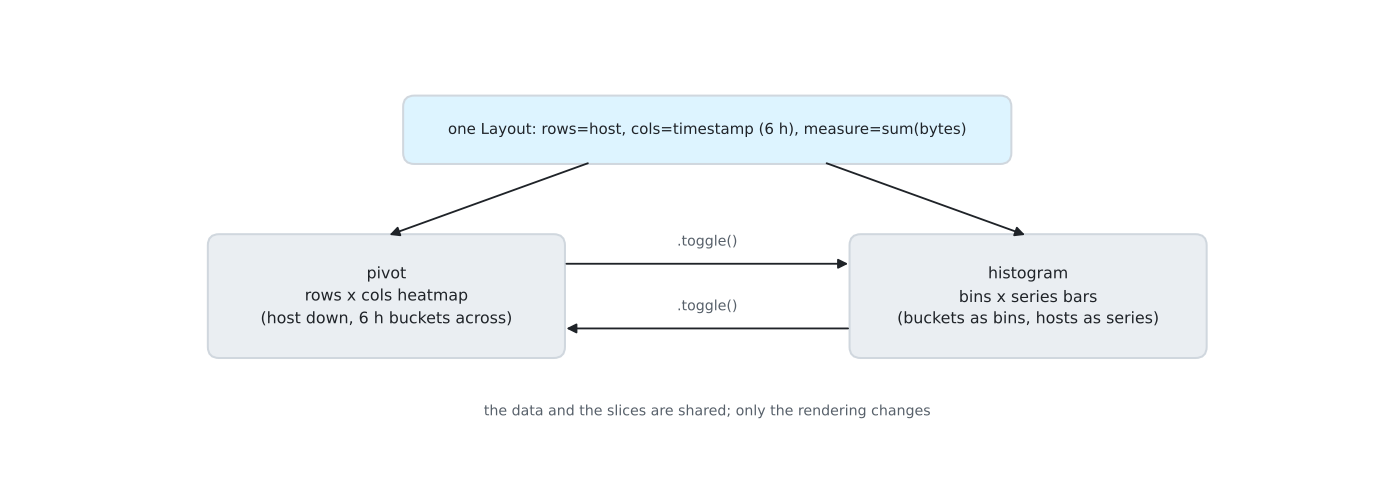

In [9]:
fig, ax = canvas(11.5, 4.2)
box(ax, 2.5, 3.1, 6.5, 0.7, "one Layout: rows=host, cols=timestamp (6 h), measure=sum(bytes)", kind="accent", fs=9)
box(ax, 0.4, 1.0, 3.8, 1.3, "pivot\nrows x cols heatmap\n(host down, 6 h buckets across)", kind="step")
box(ax, 7.3, 1.0, 3.8, 1.3, "histogram\nbins x series bars\n(buckets as bins, hosts as series)", kind="step")
arrow(ax, 4.5, 3.1, 2.3, 2.3)
arrow(ax, 7.0, 3.1, 9.2, 2.3)
arrow(ax, 4.2, 2.0, 7.3, 2.0, ".toggle()")
arrow(ax, 7.3, 1.3, 4.2, 1.3, ".toggle()")
note(ax, 5.75, 0.4, "the data and the slices are shared; only the rendering changes", ha="center", fs=8.5)
plt.show()

---

## Part 2 - Working session

It is Monday 08:00 and Anthony Romero, Gould-Foster's on-call analyst, has the weekend's merged log on disk. The questions in order: who hammered the VPN, what else moved, what appeared that was never there before, what sequence of actions the suspicious users followed, and how to hand all of it to an agent without the log leaving the machine.

### Who is hammering the VPN

Fixing `rows` and `cols` turns the fit into a plain pivot with the measure still chosen for you; `agg="count"` overrides it. `explain()` names a cell by the labels the table shows and says what sets its rows apart from the rest.

In [10]:
ips = bp.fit(logs, rows=["src_ip"], cols=["action"], agg="count")
print(ips.describe())
ips.slice(status=401).style(heat="row")

count by src_ip (top 39) x action


pivot · count by src_ip (top 39) x action · 6,860 rows of 49,167 · slices: status=401
action           login  allow download logout upload
src_ip (top 39)                                     
185.220.101.47   2,500      0        0      0      0
45.134.26.29        23      0        0      0      0
45.134.26.23        23      0        0      0      0
45.134.26.31        23      0        0      0      0
45.134.26.21        22      0        0      0      0
45.134.26.18        22      0        0      0      0
45.134.26.17        22      0        0      0      0
10.3.10.159         10      5        1      3      1
10.3.3.174           8      6        3      1      2
10.3.10.61           8      7        1      1      2
10.2.30.211          5     11        0      1      2
10.2.0.112           8      6        4      0      0
10.2.8.132          10      2        2      1      2
10.2.26.198          6      6        4      0      1
10.3.9.233           5      5        4      2      1
10.1.27.127         12      3        1      0      1
10.2.0.180           8      7        0      1      1
10.1.20.168          5      8        2      2      0
10.1.31.98           5      5        4      3      0
10.3.3.50            7      8        0      1      0
10.1.31.212          6      4        0      3      3
10.1.26.46           7      4        1      2      2
10.2.28.9            7      4        3      2      0
10.1.31.126          5      6        4      1      0
10.3.3.219           6      6        2      1      1
10.3.9.93            8      2        2      0      4
10.1.18.130          4      7        4      1      0
10.1.31.142          8      5        2      1      0
10.2.30.162          4      3        3      4      1
10.2.26.46           9      4        1      1      0
10.3.24.215          7      6        1      1      0
10.2.8.111           3      5        5      1      1
10.3.10.31           8      3        4      0      0
10.2.26.53           7      5        2      1      0
10.1.18.200          4      7        2      2      0
10.3.3.10            5      6        0      2      2
10.1.18.181          8      3        3      0      1
10.1.31.65           4      6        4      0      1
10.2.28.25           9      3        0      2      1
(other)          1,564  1,102      467    327    241

In [11]:
e = ips.explain(BRUTE_IP, "login")
print(textwrap.fill(str(e), 120))
pd.DataFrame(e["distinguishing"])[["column", "kind", "text"]]

src_ip=185.220.101.47 × action=login: count = 2,500 · ×3.5 what independence of the axes predicts (717.30) - over · 100%
of its row, 18% of its column, 5.1% of the table · rank 7 of 240 cells · 2,500 of 49,167 rows What sets these rows
apart: `country` is 'RU' for 100% of these rows vs 0% elsewhere (×201); `event` is 'login_fail' for 100% of these rows
vs 4% elsewhere (×22); `status` is '401' for 100% of these rows vs 9% elsewhere (×10); `bytes` median 443 here vs 1.92K
elsewhere (×0.23); `source` is 'auth' for 100% of these rows vs 35% elsewhere (×2.9).


,column,kind,text
0,country,label,`country` is 'RU' for 100% of these rows vs 0% elsewhere (×201)
1,event,label,`event` is 'login_fail' for 100% of these rows vs 4% elsewhere (×22)
2,status,label,`status` is '401' for 100% of these rows vs 9% elsewhere (×10)
3,bytes,numeric,`bytes` median 443 here vs 1.92K elsewhere (×0.23)
4,source,label,`source` is 'auth' for 100% of these rows vs 35% elsewhere (×2.9)


The cell holds every one of the IP's 2,500 rows (`100% of its row`), 3.5 times what independence of the axes predicts, and the distinguishing columns say the rest: country `RU` (x201 over the rest of the data), `login_fail`, status `401`, source `auth`, byte counts a quarter of the median. `rows()` returns the raw records behind the same cell.

In [12]:
ips.rows(BRUTE_IP, "login", n=5)[["timestamp", "user", "host", "status", "country", "user_agent"]]

,timestamp,user,host,status,country,user_agent
5873,2026-10-31 03:10:01.700088126,schwartzemma,vpn-05.jones.com,401,RU,"Mozilla/5.0 (iPhone; CPU iPhone OS 17_3 like Mac OS X) AppleWebKit/534.1 (KHTML, like ..."
5874,2026-10-31 03:10:02.039511694,lorettasingh,vpn-06.jones.com,401,RU,"Mozilla/5.0 (iPhone; CPU iPhone OS 17_3 like Mac OS X) AppleWebKit/534.1 (KHTML, like ..."
5875,2026-10-31 03:10:03.078002277,richardsallison,vpn-05.jones.com,401,RU,"Mozilla/5.0 (iPhone; CPU iPhone OS 11_4_1 like Mac OS X) AppleWebKit/533.0 (KHTML, lik..."
5876,2026-10-31 03:10:04.213826097,jamescollins,vpn-01.jones.com,401,RU,Mozilla/5.0 (compatible; MSIE 6.0; Windows NT 6.1; Trident/5.0)
5877,2026-10-31 03:10:04.594720267,twaller,vpn-01.jones.com,401,RU,"Mozilla/5.0 (iPhone; CPU iPhone OS 17_3 like Mac OS X) AppleWebKit/534.1 (KHTML, like ..."


### Drill levels: /24 subnets and hour of day

`src_ip` was recognised as `ipv4`, which unlocks a drill hierarchy (`/8`, `/16`, `/24`, host); a datetime column gets the minute-to-year ladder plus cyclic `hour_of_day` and `weekday`. `coarser()` walks one step up; `level()` jumps.

In [13]:
subnets_v = ips.coarser("src_ip")
print(subnets_v.describe())
subnets_v.pivot().head(8)

count by src_ip (/24) x action


action,allow,login,download,logout,deny,upload
src_ip (/24),,,,,,
10.1.26.0/24,1113,830,1384,321,242,232
10.3.9.0/24,1276,813,596,309,235,230
10.2.8.0/24,1199,862,520,325,257,241
10.2.28.0/24,1157,814,501,343,263,208
10.3.24.0/24,1100,821,527,328,244,238
10.2.0.0/24,1134,867,474,299,253,220
10.3.10.0/24,1124,773,497,339,256,252
10.3.3.0/24,1147,801,471,319,253,241


In [14]:
hod = bp.fit(logs, rows=[{"column": "timestamp", "freq": "hour_of_day"}], cols=["event"], agg="count")
hod.style(heat="column")

pivot · count by timestamp (hour of day) x event · 49,167 rows
event                    allow login_ok download logout login_fail deny upload
timestamp (hour of day)                                                       
00h                        508      314      185    141         62  105     89
01h                        458      310      218    121         55  115    108
02h                        486      301      649    138         46  116     99
03h                        476      346      673    157      2,682  105    101
04h                        497      312      195    119         65  117     81
05h                        491      270      202    133         52  112    101
06h                        457      300      203    133         56  107     93
07h                        491      317      212    150         47   98     83
08h                        709      419      315    206         87  167    144
09h                        679      450      306    214         83  191    156
10h                        741      422      319    214         83  159    170
11h                        751      448      325    198         72  175    154
12h                        709      419      335    201         79  160    133
13h                        710      435      320    204         84  180    151
14h                        746      444      334    197         73  154    137
15h                        724      439      344    221         89  164    145
16h                        707      420      365    211         82  170    132
17h                        713      457      316    213         95  179    137
18h                      1,091      656      457    323        141  233    214
19h                      1,148      674      514    304        100  225    220
20h                      1,082      667      537    302        119  219    221
21h                        512      287      257    151         60  108    111
22h                        452      304      198    126         50  106     96
23h                        495      281      202    135         53   87    106

Two rows glow in the `login_fail` column: `03h` (the brute force, Saturday) and nothing else close. The `download` column has its own `02h`/`03h` bump from the off-hours user. An hour-of-day table collapses three days into 24 rows, which is why cyclic buckets are tried by the fit as alternative dimensions.

### Histograms and bin rules

`histogram(column, by=...)` plans bins once for the whole column and draws one series per `by` value. Byte counts span six decades, so `auto` switches to 1-2-5 log bins.

In [15]:
v.histogram("bytes", by="source")

hist · count by bytes (bins) x source · 49,167 rows
bytes (bins)  auth                        firewall                    proxy                     
[0, 1)        ▏                        2  ▏                        2                           0
[1, 2)        ▏                        4  ▏                        3  ▏                        1
[2, 5)        ▏                       22  ▏                       23  ▏                       12
[5, 10)       ▎                       47  ▎                       55  ▏                       23
[10, 20)      ▋                      115  ▊                      148  ▌                       91
[20, 50)      █▉                     360  ██▏                    402  █▍                     254
[50, 100)     ███▌                   649  ███▊                   692  ██▎                    415
[100, 200)    █████▏                 953  █████▊               1.08K  ███▋                   689
[200, 500)    ████████████████████ 3.74K  ███████████▉         2.22K  ███████▊             1.46K
[500, 1K)     ███████████████▋     2.92K  ███████████▉         2.23K  ███████▌             1.39K
[1K, 2K)      ███████████▊         2.19K  ████████████▊        2.38K  ████████▌             1.6K
[2K, 5K)      ██████████████▊      2.76K  ████████████████▉    3.15K  ███████████▏         2.09K
[5K, 10K)     █████████▍           1.75K  ██████████▊          2.02K  ███████▋             1.43K
[10K, 20K)    ███████▏             1.33K  ███████▍             1.38K  ████▉                  917
[20K, 50K)    █████▍               1.02K  ██████▋              1.24K  ████▍                  810
[50K, 100K)   ██▍                    434  ██▍                    446  ██▊                    514
[100K, 200K)  █▏                     213  █▎                     245  ██▍                    448
[200K, 500K)  ▋                      117  ▊                      139  █▉                     361
[500K, 1M)    ▏                       16  ▏                       33  ▍                       68
[1M, 2M)      ▏                       16  ▏                       14  ▏                       13
[2M, 5M)      ▏                        5                           0  ▏                        3
[5M, 10M]                              0  ▏                        1                           0

In [16]:
rules = ["auto", "fd", "sturges", "scott", "sqrt", "rice", "quantile", "kmeans"]
pd.DataFrame({
    "rule": rules,
    "bins": [len(bp.bin_edges(logs["bytes"], rule=r)) - 1 for r in rules],
    "first edges": [", ".join(f"{x:g}" for x in bp.bin_edges(logs["bytes"], rule=r)[:5]) for r in rules],
})

,rule,bins,first edges
0,auto,22,"0, 1, 2, 5, 10"
1,fd,22,"0, 1, 2, 5, 10"
2,sturges,15,"0, 1, 3, 10, 30"
3,scott,22,"0, 1, 2, 5, 10"
4,sqrt,22,"0, 1, 2, 5, 10"
5,rice,22,"0, 1, 2, 5, 10"
6,quantile,68,"0, 25, 46, 66, 87"
7,kmeans,68,"0, 1, 4, 7, 10"


| Rule | What it does | Pick it when |
| --- | --- | --- |
| `auto` | Freedman-Diaconis clamped to [Sturges, 4 x Sturges], then nice 1/2/2.5/5 edges, log-spaced if heavy-tailed | default; behaves on bytes and latencies |
| `fd` | Freedman-Diaconis (IQR-based width) | robust to outliers, can explode on heavy tails |
| `sturges` | `log2(n) + 1` bins | small n, near-normal data |
| `scott`, `sqrt`, `rice` | classic count rules | you need to match another tool's bins |
| `quantile` | equal-frequency edges | every bin should carry the same number of rows |
| `kmeans` | 1-D natural breaks | the column is multi-modal and bins should follow the modes |
| `mixture` | edges at the valleys of a fitted Gaussian mixture | same, with the mode count chosen by BIC |

On a heavy tail the count rules stop mattering: `auto`, `fd`, `scott`, `sqrt` and `rice` all ask for far more bins than a log ladder has, so they collapse to the same 22 1-2-5 edges and only `sturges` asks for fewer (and gets a coarser 1-3-10 ladder). `quantile` and `kmeans` take the `auto` *count* (68 here) and move the cuts instead, which is why they report three times as many bins. Time columns use the same idea with a ladder instead of rules:

In [17]:
v.histogram("timestamp", by="source").style(stacked=True)

hist · count by timestamp (6 h) x source · 49,167 rows
timestamp (6 h)   auth                       firewall                   proxy                    
2026-10-30 18:00  ████████▌           1.56K  █████████▋          1.75K  ██████▏             1.12K
2026-10-31 00:00  ███████████████████ 3.46K  ██████▎             1.14K  ███▊                  686
2026-10-31 06:00  █████████▉          1.79K  ███████████         2.01K  ███████▍            1.34K
2026-10-31 12:00  ████████████▏       2.22K  █████████████▋      2.49K  ████████▋           1.56K
2026-10-31 18:00  ████████▋           1.57K  █████████▋          1.76K  ██████▏             1.11K
2026-11-01 00:00  ██████▍             1.17K  ██████              1.08K  ████████▊           1.59K
2026-11-01 06:00  ██████████          1.82K  ██████████▉         1.97K  ███████             1.27K
2026-11-01 12:00  ████████████▎       2.23K  █████████████▋      2.48K  ████████▌           1.56K
2026-11-01 18:00  ████████▋           1.56K  █████████▋          1.76K  ███████▉            1.44K
2026-11-02 00:00  █████▍                982  ██████▏             1.11K  ███▊                  684
2026-11-02 06:00  █▊                    312  ██                    358  █▎                    237

### What changed, and when: `spikes()`

Every row of the current table gets a time series of the measure, and every bucket is compared with a robust baseline of that row's own other buckets (median and MAD, seasonal when three periods exist). The score is a signed robust z; `kind` separates a one-bucket spike or drop from a persistent shift.

In [18]:
ips.spikes("timestamp").head(8)

,row,bucket,kind,observed,expected,ratio,score,support,baseline
0,185.220.101.47,2026-10-31 00:00,spike,2500.0,0.0,inf,2500.00,2500,seasonal
1,10.1.26.12,2026-11-01 00:00,spike,903.0,6.0,150.500000,366.20,903,seasonal
2,(other),2026-11-02 06:00,drop,788.0,4564.0,0.172656,-55.89,788,seasonal
3,10.3.9.233,2026-11-01 18:00,spike,158.0,14.0,11.285714,38.49,158,seasonal
4,10.3.9.190,2026-11-01 18:00,spike,166.0,19.0,8.736842,9.92,166,seasonal
5,10.3.10.106,2026-10-30 18:00,spike,20.0,8.0,2.500000,4.24,20,seasonal
6,10.3.10.159,2026-10-31 06:00,spike,19.0,9.0,2.111111,3.33,19,seasonal
7,10.3.10.106,2026-10-31 12:00,spike,19.0,9.0,2.111111,3.33,19,seasonal


In [19]:
by_user = bp.fit(logs, rows=["user"], cols=["event"], agg="count")
by_user.spikes("timestamp").head(6)

,row,bucket,kind,observed,expected,ratio,score,support,baseline
0,georgemartinez,2026-11-01 00:00,spike,908.0,16.0,56.750000,54.70,908,seasonal
1,adamsandre,2026-11-02 06:00,drop,106.0,670.0,0.158209,-21.79,106,seasonal
2,ajohnson,2026-11-02 06:00,drop,69.0,356.0,0.193820,-12.10,69,seasonal
3,(other),2026-11-02 06:00,drop,300.0,1588.0,0.188917,-9.55,300,seasonal
4,amyanderson,2026-11-02 06:00,drop,31.0,144.0,0.215278,-9.42,31,seasonal
5,angela70,2026-11-02 06:00,drop,13.0,93.0,0.139785,-8.30,13,seasonal


Both planted bursts come out on top with their row counts as `support`: the brute-force IP at `2026-10-31 00:00` (the 6-hour bucket that holds 03:10-03:40, 2,500 rows against an expected 0) and the off-hours workstation `10.1.26.12` at `2026-11-01 00:00` (903 rows: the 900 planted downloads plus that machine's own three). Rows 3 and 4 are the two workstations behind the novel user agent, Sunday evening. In the per-user table the same hour shows up as the user, and the `(other)` row spiking Saturday 00:00 is the brute force's rotating usernames folded into top-N's remainder. The `drop` rows at `2026-11-02 06:00` are the Monday bucket that ends at 08:00: a partial bucket, not an incident, which is the first thing to check whenever the last bucket drops.

### What appeared: `novel()`

`novel(entity, attr, since=...)` splits the rows at a point in time and checks every entity seen after it against the history before it. Four kinds come back: new entity, new pair, new value, fan-out. `since` is a fraction of the span, a duration back from the end, or a moment.

In [20]:
cols = ["kind", "entity", "value", "before", "after", "peers", "score"]
new_ips = v.novel("src_ip", "host", since="2026-10-31", n=400)
display(new_ips.head(4)[cols])
display(new_ips[new_ips.kind == "new entity"].head(3)[cols])
display(v.novel("country", "user", since="24h").head(3)[cols])
v.novel("user_agent", "user").head(3)[cols]

,kind,entity,value,before,after,peers,score
0,fan-out,10.2.30.178,NaN,1,30,NaN,19.590
1,fan-out,10.2.0.103,NaN,3,29,NaN,14.264
2,fan-out,10.2.30.138,NaN,3,29,NaN,14.264
3,fan-out,10.3.24.120,NaN,3,29,NaN,14.264


,kind,entity,value,before,after,peers,score
4,new entity,185.220.101.47,NaN,0,2500,NaN,13.873
203,new entity,175.45.176.9,NaN,0,40,NaN,7.943


,kind,entity,value,before,after,peers,score
0,new entity,KP,NaN,0,40,NaN,9.605
1,new pair,BR,raymondrangel,0,6,8.0,2.959
2,new pair,FR,nguyenmatthew,0,5,8.0,2.737


,kind,entity,value,before,after,peers,score
0,new entity,python-requests/2.31.0,NaN,0,300,NaN,9.819
1,new pair,"Mozilla/5.0 (iPad; CPU iPad OS 5_1_1 like Mac OS X) AppleWebKit/536.1 (KHTML, like Gec...",kaylaanderson,0,3,10.0,2.348


Read the first table critically: the top rows are `fan-out` findings for ordinary workstations that had one or three rows of history before Saturday midnight and then did a normal day's work across 30 hosts. Six hours of history is too short for fan-out to mean anything, and the fix is a later `since` or a filter on `kind`. Filtered to new entities, the two planted external sources are first: `185.220.101.47` with 2,500 rows and `175.45.176.9` with 40. The other two calls land directly: `KP` is a new country in the last 24 hours and `python-requests/2.31.0` is a new user agent in the default last quarter of the span. Scores are bits-like (`log2` of the rows behind the finding plus `log2` of how rare the value was), so the brute force outranks the rare country even though both are "new".

### Surprise and comparison

`anomalies()` ranks cells by how far they sit from `row_total x col_total / grand_total`, so a big cell is not automatically a surprising one. `compare()` puts one side against the rest on a frozen layout and `drivers()` lists what else differs beyond the table's own axes.

In [21]:
cc = bp.fit(logs, rows=["country"], cols=["event"], agg="count")
display(cc.anomalies(5))
cc.style(heat="surprise")

,row,col,observed,expected,residual,direction
0,RU,login_fail,2500.0,224.490,151.873,over
1,RU,allow,0.0,805.062,-28.374,under
2,US,login_fail,1119.0,2347.896,-25.362,under
3,RU,login_ok,0.0,492.810,-22.199,under
4,RU,download,0.0,405.811,-20.145,under


pivot · count by country x event · 49,167 rows
event    allow login_ok download logout login_fail   deny upload
country                                                         
US       8,736    5,281    4,856  2,464      1,119  1,987  1,704
GB       1,563      966      690    482        185    324    326
DE       1,261      786      570    365        126    289    248
CA       1,300      757      529    356        141    271    261
IN       1,146      708      481    284        140    263    223
RU           0        0        0      0      2,500      0      0
NL         766      521      370    241         87    162    183
BR         599      401      263    188         68    141    139
FR         462      272      182    132         49    115     98
KP           0        0       40      0          0      0      0

In [22]:
c = ips.compare(status=401)
display(c.top(4)[["row", "col", "lift", "p", "only_in"]])
c.drivers().head(4)[["column", "kind", "text"]]

,row,col,lift,p,only_in
0,185.220.101.47,login,inf,0.000000e+00,status=401
1,(other),deny,0.000000,1.806785e-216,rest
2,10.1.26.12,download,0.013525,1.166058e-57,NaN
3,10.3.9.190,download,0.128483,3.317135e-05,NaN


,column,kind,text
0,event,label,`event` is 'login_fail' for 64% of status=401 vs 0% of rest (×130)
1,country,label,`country` is 'RU' for 36% of status=401 vs 0% of rest (×74)
2,bytes,numeric,`bytes` median 562 in status=401 vs 1.96K in rest (×0.29)
3,event,label,`event` is 'login_ok' for 0% of status=401 vs 23% of rest (×0.021)


`RU` x `login_fail` is the most surprising cell of the country table by a wide margin (residual 154 against the next at -28), and the `status=401` comparison's drivers say the 401s are 64% `login_fail` against 0% elsewhere, 37% `RU` against 0%, with byte counts a third of the rest. The `p` column is a raw per-cell G-test; with `k` cells in play, read anything under `0.05 / k` as "enough rows to trust the ratio".

### Chains and regimes: what follows what, per user

`chains()` builds a Markov transition matrix of `event` within each `user`, ordered by `timestamp`; transitions never cross users. The result is an ordinary pivot, so it toggles, slices and clusters like any other.

In [23]:
ch = bp.chains(logs, "event", by="user", time="timestamp", normalize=True)
ch.style(heat="row")

pivot · sum(prob) by from x to · 49 rows
to         allow login_ok download logout  deny upload login_fail
from                                                             
allow       0.35     0.20     0.15   0.10  0.08   0.07       0.05
deny        0.34     0.22     0.15   0.10  0.08   0.06       0.05
download    0.31     0.19     0.25   0.08  0.07   0.06       0.04
login_fail  0.16     0.12     0.07   0.05  0.03   0.04       0.53
login_ok    0.34     0.21     0.15   0.10  0.08   0.07       0.05
logout      0.34     0.21     0.16   0.09  0.08   0.06       0.05
upload      0.35     0.20     0.16   0.10  0.08   0.07       0.04

In [24]:
display(bp.sequences(logs, "event", by="user", time="timestamp", length=3, n=6))
bp.steady_state(bp.transition_matrix(logs, "event", by="user", time="timestamp")).round(3)

,chain,count,share,groups
0,login_fail → login_fail → login_fail,1942,0.039789,179
1,allow → allow → allow,1894,0.038806,167
2,allow → allow → login_ok,1168,0.023931,162
3,login_ok → allow → allow,1106,0.022661,161
4,download → download → download,1099,0.022517,69
5,allow → login_ok → allow,1094,0.022415,158


allow         0.322
login_ok      0.197
download      0.162
logout        0.092
login_fail    0.090
deny          0.072
upload        0.065
Name: steady_state, dtype: float64

`login_fail -> login_fail` carries over half of its row's probability while every other row sends 4-5% to `login_fail`, and the most frequent 3-step chain is three failures in a row, seen for 179 distinct users: the brute force rotated through the whole user list, which is exactly what `groups` is there to show. In the stationary distribution `login_fail` sits close to 9%, more than double its share in the baseline traffic.

`regimes()` asks a stronger question: is each user's sequence switching between a few hidden behavioural states? A Baum-Welch HMM is fitted per user sequence, the state count is picked by BIC and Viterbi decodes a regime label per row. It is `O(rows x states^2)` per EM pass, so it runs here on a 5,000-row sample.

In [25]:
t0 = time.time()
reg = bp.regimes(logs.sample(5000, random_state=7), "event", by="user", time="timestamp")
print(f"{time.time() - t0:.1f}s")
reg

27.0s


pivot · count by regime x event · 5,000 rows
event     allow login_ok download logout login_fail deny upload
regime                                                         
regime 1  1,430      919      667    436        141  350    321
regime 2    156       74       40     44        299   18     14
regime 3      0        0       91      0          0    0      0

Regimes are numbered by how common they are. `regime 1` is normal use with no failures at all, `regime 2` carries every `login_fail` in the sample, and `regime 3` is pure `download`: the "credential-stuffing" and "bulk download" states the HMM separated from normal use without being told what either looks like.

### Clustering: similar rows, and records with a noise label

`cluster(k)` groups the pivot's rows by the shape of their column profile (compared as proportions, so a busy and a quiet IP with the same mix land together). `bp.cluster(df, columns, method="dbscan")` clusters records instead and labels outliers `noise`.

With `k=4` on the source IP table, 37 of the 40 rows share one cluster and the three singletons are the two planted sources that made the top-39 list, the brute-force IP (all `login`) and the off-hours workstation (all `download`), plus the `(other)` remainder, whose profile is every action at once and matches nobody. Clustering by profile shape is a cheap way to ask "which rows do not look like the others".

In [26]:
grouped = ips.cluster(4)
print(grouped.describe())
tbl = grouped.pivot()
sizes = tbl.groupby(level=0).size()
print(sizes.to_dict())
tbl.loc[sizes[sizes == 1].index]

count by cluster > src_ip (top 39) x action
{'c1 (rows=37)': 37, 'c2 (rows=1)': 1, 'c3 (rows=1)': 1, 'c4 (rows=1)': 1}


,action,allow,login,download,logout,deny,upload
cluster,src_ip (top 39),,,,,,
c2 (rows=1),185.220.101.47,0,2500,0,0,0,0
c3 (rows=1),10.1.26.12,29,23,914,16,8,3
c4 (rows=1),(other),14014,10428,6183,4051,3166,2868


In [27]:
labelled = bp.cluster(logs, ["bytes"], method="dbscan")
labelled["cluster"].value_counts().rename("rows").to_frame().T

cluster,"c1 (n=46,836)",noise (n=945),c2 (n=929),c3 (n=222),c4 (n=61),c5 (n=60),c6 (n=45),c7 (n=31),c8 (n=21),c9 (n=17)
rows,46836,945,929,222,61,60,45,31,21,17


### Insights, LLM context and the prompt packet (no model is called)

`insights()` runs the local statistics (skew, mixtures, concentration, outliers, correlation, anomaly, spike, novelty) on whatever is in view and ranks the findings. `llm_context()` and `prompt()` package the view as markdown for a model you choose; bts-pivot never calls one.

In [28]:
report = v.insights(sensitivity=0.5)
print(report["summary"])
pd.DataFrame(report["findings"])[["kind", "significance", "text"]].head(8)

49,167 rows x 11 columns (9 categorical, 1 datetime, 1 numeric). 7 notable finding(s) at sensitivity 0.50.


,kind,significance,text
0,skew,1.000,`bytes` is strongly right-skewed (skewness 20.11) - a few very large values pull the m...
1,anomaly,1.000,db-03.jones.com / 2026-11-01 00:00 is over expectation: observed 3.561e+07 vs. expecte...
2,correlation,1.000,`action` and `event` move together (normalized mutual information 1.00).
3,outliers,0.939,"`bytes` has 14.1% of values outside 1.5x the interquartile range (outside [-9.67e+03, ..."
4,anomaly,0.886,db-01.jones.com / 2026-11-01 00:00 is over expectation: observed 3.386e+07 vs. expecte...
5,anomaly,0.877,db-04.jones.com / 2026-11-01 00:00 is over expectation: observed 3.317e+07 vs. expecte...
6,concentration,0.530,"`status` is dominated by np.int64(200): 61% of rows, vs. 17% expected if the 6 values ..."


The anomaly findings are the off-hours spike again (`db-*` hosts, Sunday 00:00, 35 MB against an expectation under 1 MB), ranked next to the skew and outlier facts about `bytes`. The perfect `action`/`event` correlation is the derived column from the setup cell: `insights()` ranks what is there, including the things you built yourself.

In [29]:
ctx = ips.llm_context(max_rows=6)
print(ctx["description"])
print(ctx["table"][:600])

Pivot table of 49,167 rows: count by src_ip (top 39) x action. Shown as 40 row(s) x 6 column(s) (table below is truncated). Most surprising cell: 185.220.101.47 / login (over expectation - observed 2,500 vs. expected 717.3).
| src_ip (top 39) | allow | login | download | logout | deny | upload |
|---|---|---|---|---|---|---|
| 185.220.101.47 | 0 | 2500 | 0 | 0 | 0 | 0 |
| 10.1.26.12 | 29 | 23 | 914 | 16 | 8 | 3 |
| 10.3.9.190 | 114 | 32 | 98 | 10 | 10 | 8 |
| 10.3.9.233 | 111 | 34 | 92 | 12 | 6 | 10 |
| 10.2.0.203 | 60 | 36 | 16 | 11 | 8 | 7 |
| 10.3.3.26 | 44 | 36 | 29 | 12 | 10 | 7 |

_truncated to 6 of 40 rows x 6 of 6 columns_


In [30]:
p = ips.slice(status=401).prompt("Which source IP deserves a block rule, and what evidence supports it?")
print("prompt size: ~%d tokens" % p.tokens)
print(str(p)[:900])

prompt size: ~852 tokens
# Data analysis request

The facts below were computed locally by bts-pivot from the actual data; nothing here is invented or sampled from a model. Reason only from these facts, and quote specific cells and numbers when you do.

## Dataset

6,860 rows in view (of 49,167 in the source), 11 columns.

- `timestamp`: datetime, ~every 9.9s; 6,860 distinct; e.g. 2026-10-30 18:03:56.7..., 2026-10-30 18:04:25.5..., 2026-10-30 18:04:34.3...
- `source`: categorical; 3 distinct; e.g. auth, firewall, proxy
- `src_ip`: categorical, ipv4; 427 distinct; e.g. 10.2.8.132, 10.3.10.57, 10.3.24.75
- `user`: categorical; 180 distinct; e.g. michael04, driley, adamsandre
- `host`: categorical, domain; 30 distinct; e.g. vpn-03.jones.com, mail-01.jones.com, mail-04.jones.com
- `action`: categorical; 5 distinct; e.g. login, upload, logout
- `status`: constant; 1 distinct; e.g. 401
- `bytes`: numeric; 3,186 distin


The packet starts by telling the model to rely only on the facts below, then gives the profile, the sliced table and the most surprising cells. To send it somewhere, guard the call: `if os.environ.get("ANTHROPIC_API_KEY"): ...` with `anthropic.Anthropic().messages.create(...)` and `str(p)` as the user message; this notebook stops at the packet.

### HTML export

`html()` and `svg()` return self-contained markup with no JavaScript. Styles (`theme`, `heat`, `totals`, `bars`, `sparklines`) are part of the view, so what you export is what you saw.

In [31]:
OUT = "work/06-bts-pivot"
os.makedirs(OUT, exist_ok=True)
styled = ips.slice(status=401).style(theme="graphite", heat="row", totals=True, bars=True, sparklines="timestamp")
with open(f"{OUT}/vpn-401.html", "w") as f:
    f.write(styled.html())
with open(f"{OUT}/bytes-hist.svg", "w") as f:
    f.write(v.histogram("bytes", by="source").svg())
print({p: f"{os.path.getsize(p) / 1024:.0f} KB" for p in (f"{OUT}/vpn-401.html", f"{OUT}/bytes-hist.svg")})
styled

{'work/06-bts-pivot/vpn-401.html': '136 KB', 'work/06-bts-pivot/bytes-hist.svg': '19 KB'}


pivot · count by src_ip (top 39) x action · 6,860 rows of 49,167 · slices: status=401
action           login  allow download logout upload
src_ip (top 39)                                     
185.220.101.47   2,500      0        0      0      0
45.134.26.29        23      0        0      0      0
45.134.26.23        23      0        0      0      0
45.134.26.31        23      0        0      0      0
45.134.26.21        22      0        0      0      0
45.134.26.18        22      0        0      0      0
45.134.26.17        22      0        0      0      0
10.3.10.159         10      5        1      3      1
10.3.3.174           8      6        3      1      2
10.3.10.61           8      7        1      1      2
10.2.30.211          5     11        0      1      2
10.2.0.112           8      6        4      0      0
10.2.8.132          10      2        2      1      2
10.2.26.198          6      6        4      0      1
10.3.9.233           5      5        4      2      1
10.1.27.127         12      3        1      0      1
10.2.0.180           8      7        0      1      1
10.1.20.168          5      8        2      2      0
10.1.31.98           5      5        4      3      0
10.3.3.50            7      8        0      1      0
10.1.31.212          6      4        0      3      3
10.1.26.46           7      4        1      2      2
10.2.28.9            7      4        3      2      0
10.1.31.126          5      6        4      1      0
10.3.3.219           6      6        2      1      1
10.3.9.93            8      2        2      0      4
10.1.18.130          4      7        4      1      0
10.1.31.142          8      5        2      1      0
10.2.30.162          4      3        3      4      1
10.2.26.46           9      4        1      1      0
10.3.24.215          7      6        1      1      0
10.2.8.111           3      5        5      1      1
10.3.10.31           8      3        4      0      0
10.2.26.53           7      5        2      1      0
10.1.18.200          4      7        2      2      0
10.3.3.10            5      6        0      2      2
10.1.18.181          8      3        3      0      1
10.1.31.65           4      6        4      0      1
10.2.28.25           9      3        0      2      1
(other)          1,564  1,102      467    327    241

### Big files: survey, plan, page

A path is **surveyed** before it is loaded (exact row count from Parquet metadata, bytes per row calibrated on a probe, the machine's RAM including cgroup limits) and a plan follows: `full`, `downcast` or `paged`. The weekend file is small, so a 10x copy and an artificially tight budget force the paged path.

In [32]:
logs.to_parquet(f"{OUT}/weekend.parquet", index=False)
pd.concat([logs] * 10, ignore_index=True).to_parquet(f"{OUT}/ten-weekends.parquet", index=False)
print(bp.survey(f"{OUT}/ten-weekends.parquet").summary())
print()
print(bp.survey(f"{OUT}/ten-weekends.parquet", memory_budget_mb=20).plan)

parquet: 4.9 MB on disk, 491,670 rows x 11 columns, ~127 MB in memory (259 B/row)
machine: 6,072 MB free of 8,022 MB; 2 CPUs, load 4.50, this process 330 MB
budget: 3,036 MB -> fits; plan: full load

Plan(mode='paged', page_rows=20000, n_pages=25, sample_rows=23176, columns=None, reasons=['~127 MB exceeds the 20 MB budget'])


In [33]:
bp.verbose()
paged = bp.fit(f"{OUT}/ten-weekends.parquet", memory_budget_mb=20, rows=["country"], cols=["event"], agg="count",
               columns=["timestamp", "country", "event", "bytes"])
bp.verbose(False)
print(paged.paged)
print(paged.title(), "| approximate:", paged.approximate)
paged.pivot().head(4)

08:11:04  survey       parquet: 491,670 rows, ~20 MB -> choke, paged    0.00s  cpu  0.00s  mem     +0 MB


08:11:04  plan         paged: 7 pages of 73,467 rows, fit on a 146,934-row sample, 4 columns; ~20 MB exceeds the 20 MB budget


08:11:04  sample       146,934 rows, 6 MB    0.12s  cpu  0.06s  mem    +36 MB


08:11:04  fit          146,934 rows x 4 cols -> count by country x event    0.06s  cpu  0.03s  mem     +0 MB


<PagedSource work/06-bts-pivot/ten-weekends.parquet: 491,670 rows in 7 pages; sample 146,934 rows>


pivot · count by country x event · ≈491,670 rows (paged, 7 pages) | approximate: False


event,allow,login_ok,download,logout,login_fail,deny,upload
country,,,,,,,
US,87360,52810,48560,24640,11190,19870,17040
GB,15630,9660,6900,4820,1850,3240,3260
DE,12610,7860,5700,3650,1260,2890,2480
CA,13000,7570,5290,3560,1410,2710,2610


The log shows the plan (pages, sample size, the reason), the fit on the sample and one line per page. `count`, `sum`, `min`, `max` and `mean` are exact across pages; `median`, `std` and `nunique` fall back to the sample and the title says `approximate`. Top-N buckets are frozen from the sample so every page folds the same way.

A DuckDB source is a URL, and `engine="duckdb"` runs the group-by of an in-memory frame as SQL against DuckDB when every dimension can be expressed there.

In [34]:
import duckdb
con = duckdb.connect(f"{OUT}/weekend.duckdb")
con.execute(f"CREATE OR REPLACE TABLE events AS SELECT * FROM '{OUT}/weekend.parquet'")
con.close()
from_duck = bp.fit(f"duckdb://{OUT}/weekend.duckdb?table=events", rows=["host"], cols=["event"], agg="count")
print(from_duck.title())

t0 = time.time(); pandas_v = bp.fit(logs, rows=["country"], cols=["event"], agg="count"); t_pandas = time.time() - t0
t0 = time.time(); duck_v = bp.fit(logs, rows=["country"], cols=["event"], agg="count", engine="duckdb"); t_duck = time.time() - t0
print(f"engine={duck_v.options.engine}: same table = {duck_v.pivot().equals(pandas_v.pivot())}; "
      f"pandas {t_pandas:.2f}s vs duckdb {t_duck:.2f}s (first call pays the registration)")

pivot · count by host x event · 49,167 rows


engine=duckdb: same table = True; pandas 0.09s vs duckdb 0.08s (first call pays the registration)


### The CLI

`bts-pivot FILE` prints the text rendering; `--hist`, `--slice`, `--chains` and `--survey` mirror the Python calls. `python -m bts_pivot` is the same entry point. `--demo auth` and `bp.sample.auth_logs()` give the built-in synthetic datasets when you have no file at hand.

In [35]:
for args in (["bts-pivot", f"{OUT}/weekend.parquet", "--rows", "source", "--cols", "event", "--count", "--width", "110"],
             ["bts-pivot", f"{OUT}/weekend.parquet", "--slice", "status=401", "--hist", "--on", "bytes", "--by", "source", "--width", "110"],
             ["bts-pivot", f"{OUT}/weekend.parquet", "--chains", "event", "--by", "user", "--time", "timestamp", "--width", "110"],
             [sys.executable, "-m", "bts_pivot", "--demo", "auth", "--layout"]):
    r = subprocess.run(args, text=True, capture_output=True)
    print("$", " ".join(args[-6:]), "-> exit", r.returncode)
    print("\n".join(r.stdout.splitlines()[:9]), "\n")

$ source --cols event --count --width 110 -> exit 0
pivot · count by source x event · 49,167 rows
event     allow login_ok download logout login_fail   deny upload
source                                                           
auth      5,548    3,490    2,437  1,603      3,253  1,206  1,132
firewall  6,163    3,836    2,726  1,755        731  1,448  1,252
proxy     4,122    2,366    2,818  1,154        431    898    798 



$ --on bytes --by source --width 110 -> exit 0
hist · count by bytes (bins) x source · 6,860 rows of 49,167 · slices: status=401
bytes (bins)  auth                            firewall                        proxy                         
[0, 1)        ▏                            1                               0                               0
[1, 2)        ▏                            1                               0                               0
[2, 5)        ▏                            4  ▏                            1                               0
[5, 10)       ▏                            4  ▏                            5  ▏                            1
[10, 20)      ▏                           13  ▏                           12  ▏                            8
[20, 50)      ▍                           32  ▍                           33  ▍                           27
[50, 100)     ▊                           61  ▊                           65  ▍                           35

$ --by user --time timestamp --width 110 -> exit 0
pivot · sum(count) by from x to · 49 rows
to          allow login_ok download logout   deny upload login_fail
from                                                               
allow       5,461    3,226    2,443  1,551  1,241  1,115        739
deny        1,195      770      517    370    282    224        182
download    2,473    1,515    2,025    655    525    441        318
login_fail    724      517      305    209    148    166      2,340
login_ok    3,280    2,040    1,464    961    728    710        459
logout      1,535      943      703    416    369    290        238 



$ /usr/local/bin/python3 -m bts_pivot --demo auth --layout -> exit 0
count by host x event > method 



In [36]:
demo = bp.sample.auth_logs(n=3000)
print(demo.columns.tolist())
bp.fit(demo).describe()

['timestamp', 'user', 'host', 'event', 'method', 'src_ip', 'latency_ms', 'mfa']


'count by host x event > method'

### The Jupyter explorer

`bp.explore(df)` opens an ipywidgets app: draggable field chips, a Pivot/Histogram/Chains toggle, Best fit and Suggest, slicer widgets, Inspect (click a cell), Compare, Insights, Style, Code (the Python reproducing the current view), Export and a Timeline of checkpoints. Widgets need a live kernel, which an executed-and-committed notebook does not have, so the cell below builds the explorer and shows `snapshot_html()`, a static picture of the interface.

```python
ex = bp.explore(logs)              # the live app; files and DuckDB sources are surveyed and paged
ex.select_tab("Inspect")           # tabs by name
ex.save_checkpoint("baseline")     # bookmark layout, slices, style; the Timeline slider scrubs through them
ex.paint("src_ip", "red")          # mark a field as the interesting one
ex.code                            # the Python that reproduces what is on screen
ex.view                            # the current View, usable from code
```

In [37]:
ex = bp.explore(logs.sample(5000, random_state=7))
snapshot = ex.snapshot_html()
print(type(ex).__name__, "| tabs:", ", ".join(ex.tab_names()[:8]), "...")
HTML(snapshot)

Explorer | tabs: Fields, Layout, Slicers, Histogram, Inspect, Compare, Insights, Reduce & cluster ...


### The MCP server: an agent asks, the log stays on disk

`bts-pivot-mcp` is a stdio MCP server: the client (Claude Code, Claude Desktop, your own agent) spawns it as a subprocess and talks JSON-RPC over stdin/stdout. Every tool takes a `source` path, routes through the same `fit()`, and a file too big for RAM is paged exactly as above. Nothing is uploaded anywhere.

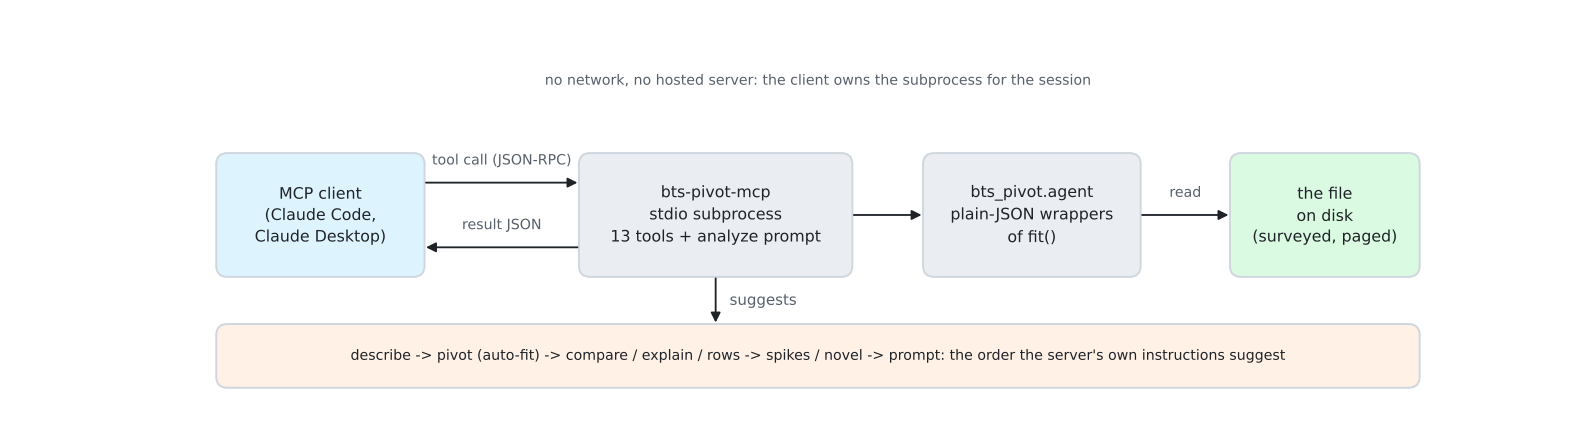

In [38]:
fig, ax = canvas(13.3, 3.7)
note(ax, 6.65, 3.4, "no network, no hosted server: the client owns the subprocess for the session", ha="center", fs=8.5)
box(ax, 0.2, 1.3, 2.2, 1.3, "MCP client\n(Claude Code,\nClaude Desktop)", kind="accent")
box(ax, 4.1, 1.3, 2.9, 1.3, "bts-pivot-mcp\nstdio subprocess\n13 tools + analyze prompt", kind="step")
box(ax, 7.8, 1.3, 2.3, 1.3, "bts_pivot.agent\nplain-JSON wrappers\nof fit()", kind="step")
box(ax, 11.1, 1.3, 2.0, 1.3, "the file\non disk\n(surveyed, paged)", kind="good")
arrow(ax, 2.4, 2.3, 4.1, 2.3, "tool call (JSON-RPC)")
arrow(ax, 4.1, 1.6, 2.4, 1.6, "result JSON")
arrow(ax, 7.0, 1.95, 7.8, 1.95)
arrow(ax, 10.1, 1.95, 11.1, 1.95, "read")
box(ax, 0.2, 0.1, 12.9, 0.65, "describe -> pivot (auto-fit) -> compare / explain / rows -> spikes / novel -> prompt: the order the server's own instructions suggest", kind="warn", fs=8.5)
arrow(ax, 5.55, 1.3, 5.55, 0.75)
note(ax, 5.7, 1.02, "suggests")
plt.show()

The config for Claude Desktop (`claude_desktop_config.json`) or a project-level `.mcp.json` for Claude Code; `uvx` fetches the package on first use and needs nothing installed. The one-line equivalent is `claude mcp add bts-pivot -- uvx --from "bts-pivot[mcp]" bts-pivot-mcp`.

In [39]:
mcp_config = {"mcpServers": {"bts-pivot": {"command": "uvx", "args": ["--from", "bts-pivot[mcp]", "bts-pivot-mcp"]}}}
print(json.dumps(mcp_config, indent=2))

{
  "mcpServers": {
    "bts-pivot": {
      "command": "uvx",
      "args": [
        "--from",
        "bts-pivot[mcp]",
        "bts-pivot-mcp"
      ]
    }
  }
}


The tool list, read straight from the server object (works with `mcp` 1.x `FastMCP` and 2.x `MCPServer`):

In [40]:
import bts_pivot.mcp_server as mcp_server

tools = await mcp_server.server.list_tools()
def schema(t):
    return getattr(t, "input_schema", None) or getattr(t, "inputSchema")
pd.DataFrame({
    "tool": [t.name for t in tools],
    "answers": [t.description.split(". ")[0].split(": ")[0][:70] for t in tools],
    "arguments": [", ".join(k for k in schema(t)["properties"] if k != "source")[:60] for t in tools],
})

,tool,answers,arguments
0,describe,Profile a data source,"columns, memory_budget_mb, distributions"
1,pivot,"Build a pivot table (rows x columns of an aggregated measure) or, with","rows, cols, values, agg, filters, mode, on, by, bins, max_ro"
2,llm_context,"Same arguments as pivot(), but returns {""description"", ""metadata"", ""ta","rows, cols, values, agg, filters, mode, on, by, bins, max_ro"
3,insights,"A rich, local, non-LLM analysis of the data (optionally filtered)","rows, cols, values, agg, filters, sensitivity, max_findings,"
4,compare,Compare two sides of the data cell by cell on one shared pivot layout,"split, vs, metric, n, rows, cols, values, agg, filters, max_"
5,rows,The raw rows behind one cell of a pivot() table (or one bar of its his,"cell, n, rows, cols, values, agg, filters, mode, on, by, bin"
6,explain,Why does this cell look the way it does? `cell` names it as in rows(),"cell, n_rows, k, rows, cols, values, agg, filters, mode, on,"
7,prompt,"One self-contained analysis prompt as markdown text, built from facts","question, table, profile, anomalies, insights, sensitivity,"
8,suggest,"List the n best pivot layouts for this data, best first, each with a d","n, filters"
9,slicers,"The most frequent values (with counts) per label-like column, for buil","columns, top"


A real round trip: spawn `bts-pivot-mcp` the way a client does, initialise, list tools and call `novel` against the Parquet file on disk. Inside Jupyter the cell can `await` directly.

In [41]:
from mcp import ClientSession
from mcp.client.stdio import StdioServerParameters, stdio_client

async def ask_server():
    async with stdio_client(StdioServerParameters(command="bts-pivot-mcp")) as (read, write):
        async with ClientSession(read, write) as session:
            init = await session.initialize()
            listed = await session.list_tools()
            prompts = await session.list_prompts()
            result = await session.call_tool("novel", {"source": f"{OUT}/weekend.parquet", "entity": "country",
                                                        "attr": "user", "since": "24h", "n": 2})
            return init, [t.name for t in listed.tools], [p.name for p in prompts.prompts], json.loads(result.content[0].text)

init, names, prompt_names, answer = await ask_server()
print("server:", getattr(init, "server_info", getattr(init, "serverInfo", None)).name, "| tools:", len(names), "| prompts:", prompt_names)
print("instructions start:", init.instructions[:110], "...")
pd.DataFrame(answer["findings"])[["kind", "entity", "before", "after", "score", "text"]]

server: bts-pivot | tools: 13 | prompts: ['analyze']
instructions start: Pivot and explore tabular data (CSV/TSV/JSON/JSONL/Parquet/DuckDB, or inline records). Start with describe() t ...


,kind,entity,before,after,score,text
0,new entity,KP,0,40,9.605,"country KP is new: first seen since 2026-11-01 07:59, 40 row(s) over 19 distinct user"
1,new pair,BR,0,6,2.959,country BR → user raymondrangel is a new pair: not before 2026-11-01 07:59; raymondran...


The server came back with the same `KP` finding the in-process call produced, as JSON an agent can quote. `bts_pivot.agent` is the same surface without MCP: every function takes and returns only JSON-safe values, for any tool-calling framework.

In [42]:
from bts_pivot import agent
d = agent.describe(f"{OUT}/weekend.parquet")
print({k: d[k] for k in d if k not in ("columns",)})
pd.DataFrame(d["columns"])[["name", "kind", "semantic", "nunique", "null_frac"]]

{'survey': {'source': 'work/06-bts-pivot/weekend.parquet', 'format': 'parquet', 'disk_mb': 0.91, 'rows': 49167, 'rows_exact': True, 'estimated_memory_mb': 12.7, 'plan': 'full', 'plan_summary': 'full load'}, 'rows_profiled': 20000, 'is_time_series': False, 'time_column': 'timestamp'}


,name,kind,semantic,nunique,null_frac
0,timestamp,datetime,NaN,20000,0.0
1,source,categorical,NaN,3,0.0
2,src_ip,categorical,ipv4,421,0.0
3,user,categorical,NaN,180,0.0
4,host,categorical,domain,30,0.0
5,action,categorical,NaN,6,0.0
6,status,categorical,NaN,6,0.0
7,bytes,numeric,NaN,8585,0.0
8,country,categorical,NaN,9,0.0
9,user_agent,categorical,NaN,12,0.0


In [43]:
sp = agent.spikes(f"{OUT}/weekend.parquet", rows=["src_ip"], cols=["event"], agg="count", n=3)
print(sp["layout"], "|", sp["spikes"][0]["text"])
pd.DataFrame(sp["spikes"])[["row", "bucket", "kind", "observed", "expected", "score", "support"]]

count by src_ip (top 39) x event | 185.220.101.47: count spikes to 2,500 at timestamp 2026-10-31 00:00 vs 0 expected, +2500.0 spreads, 2,500 row(s)


,row,bucket,kind,observed,expected,score,support
0,185.220.101.47,2026-10-31 00:00,spike,2500.0,0.0,2500.00,2500
1,10.1.26.12,2026-11-01 00:00,spike,903.0,6.0,366.20,903
2,(other),2026-11-02 06:00,drop,788.0,4564.0,-55.89,788


---

## Part 3 - Solving a critical problem

### The Sunday 03:00 credential-stuffing run the dashboard never showed

Saturday's brute force was loud: 2,500 failures from one IP in thirty minutes, blocked by 09:00, ticket closed. Sunday looked quiet on the SOC dashboard, which plots events per six hours and logins per six hours. Monday 08:00, Anthony Romero is about to close the weekend when a `db-*` owner mentions a VPN session from an account whose user was on holiday.

**What goes wrong if this is not solved today**: a credential-stuffing run tests leaked passwords two or three times per account, slowly, from a few IPs, and every success is a valid VPN session that survives the IP block. By Tuesday the attacker has a foothold on the jump hosts, the IAM lead gets paged at 02:00 to force-reset the whole directory, and the incident report has to say when it started and which accounts it reached. The totals cannot answer any of that: 180 rows inside a bucket of three thousand do not move a line chart.

**Approach**: stop looking at totals. Pivot the auth log by hour and status for Sunday, toggle to see the shape, ask `spikes()` and `novel()` what moved and what appeared on the `user_agent` axis, read the per-user Markov chain for the fail-fail-success signature, slice to the sources, name the accounts, export the table for the ticket.

The dashboard view first, so the gap is on record.

In [44]:
auth = bp.fit(logs, rows=[{"column": "timestamp", "freq": "6h"}], cols=["source"], agg="count")
dash = auth.pivot()["auth"].rename("auth events per 6 h").to_frame()
dash["logins"] = v.slice(action="login").histogram("timestamp", bins=11).bins().iloc[:, 0].values
dash.loc[["2026-10-31 00:00", "2026-11-01 00:00", "2026-11-02 00:00"]]

,auth events per 6 h,logins
timestamp (6 h),,
2026-10-31 00:00,3461,3211
2026-11-01 00:00,1170,884
2026-11-02 00:00,982,720


Saturday 00:00 carries the brute force; Sunday 00:00 is lower than Saturday on both counters and within a few percent of Monday's same bucket. Nothing on this table pages anyone. Now the same hours as a pivot of **hour x status**, logins only, Sunday only.

In [45]:
sunday = bp.fit(logs, rows=[{"column": "timestamp", "freq": "h"}], cols=["status"], agg="count").slice(timestamp="2026-11-01", action="login")
print(sunday.title())
sunday.style(heat="column")

pivot · count by timestamp (hour) x status · 4,865 rows of 49,167 · slices: timestamp=2026-11-01 & action=login


pivot · count by timestamp (hour) x status · 4,865 rows of 49,167 · slices: timestamp=2026-11-01 & action=login
status            200 302  401 403 404 500
timestamp (hour)                          
2026-11-01 00:00   81   7   22  10   6   0
2026-11-01 01:00   85  12   19   5   4   3
2026-11-01 02:00   74   7   15   8   2   3
2026-11-01 03:00  124  10  146   5   6   4
2026-11-01 04:00   69  12   16  10   6   1
2026-11-01 05:00   75   8   15   4   3   7
2026-11-01 06:00   74  11   19   7   8   2
2026-11-01 07:00   80  15   13   5   8   4
2026-11-01 08:00  159  29   44   8  10   5
2026-11-01 09:00  156  28   41  16  15   8
2026-11-01 10:00  163  23   52   6  17   3
2026-11-01 11:00  143  24   38   8  16   4
2026-11-01 12:00  159  29   40   9  10   5
2026-11-01 13:00  167  26   41  11  10   5
2026-11-01 14:00  177  22   33  10  14   2
2026-11-01 15:00  180  21   38  15  21   3
2026-11-01 16:00  163  20   46  13  10   3
2026-11-01 17:00  178  25   51   8  10   5
2026-11-01 18:00  178  28   57  11  17   7
2026-11-01 19:00  141  25   34   9   6   3
2026-11-01 20:00  171  29   41  18   8   4
2026-11-01 21:00   71   7   23   3   6   1
2026-11-01 22:00   79  15   18   4   9   2
2026-11-01 23:00   68  14   15   7   8   2

In [46]:
sunday.toggle().style(stacked=True)

hist · count by timestamp (hour) x status · 4,865 rows of 49,167 · slices: timestamp=2026-11-01 & action=login
timestamp (hour)  200          302          401          403          404          500        
2026-11-01 00:00  ███▏     81  ▎         7  ▉        22  ▍        10  ▎         6            0
2026-11-01 01:00  ███▎     85  ▌        12  ▊        19  ▎         5  ▏         4  ▏         3
2026-11-01 02:00  ██▉      74  ▎         7  ▋        15  ▎         8  ▏         2  ▏         3
2026-11-01 03:00  ████▉   124  ▍        10  █████▋  146  ▎         5  ▎         6  ▏         4
2026-11-01 04:00  ██▋      69  ▌        12  ▋        16  ▍        10  ▎         6  ▏         1
2026-11-01 05:00  ██▉      75  ▎         8  ▋        15  ▏         4  ▏         3  ▎         7
2026-11-01 06:00  ██▉      74  ▍        11  ▊        19  ▎         7  ▎         8  ▏         2
2026-11-01 07:00  ███▏     80  ▋        15  ▌        13  ▎         5  ▎         8  ▏         4
2026-11-01 08:00  ██████▏ 159  █▏       29  █▊       44  ▎         8  ▍        10  ▎         5
2026-11-01 09:00  ██████▏ 156  █▏       28  █▋       41  ▋        16  ▋        15  ▎         8
2026-11-01 10:00  ██████▍ 163  ▉        23  ██       52  ▎         6  ▋        17  ▏         3
2026-11-01 11:00  █████▌  143  ▉        24  █▌       38  ▎         8  ▋        16  ▏         4
2026-11-01 12:00  ██████▏ 159  █▏       29  █▌       40  ▍         9  ▍        10  ▎         5
2026-11-01 13:00  ██████▌ 167  █        26  █▋       41  ▍        11  ▍        10  ▎         5
2026-11-01 14:00  ██████▉ 177  ▉        22  █▎       33  ▍        10  ▌        14  ▏         2
2026-11-01 15:00  ███████ 180  ▉        21  █▌       38  ▋        15  ▉        21  ▏         3
2026-11-01 16:00  ██████▍ 163  ▊        20  █▊       46  ▌        13  ▍        10  ▏         3
2026-11-01 17:00  ██████▉ 178  █        25  ██       51  ▎         8  ▍        10  ▎         5
2026-11-01 18:00  ██████▉ 178  █▏       28  ██▎      57  ▍        11  ▋        17  ▎         7
2026-11-01 19:00  █████▌  141  █        25  █▍       34  ▍         9  ▎         6  ▏         3
2026-11-01 20:00  ██████▋ 171  █▏       29  █▋       41  ▊        18  ▎         8  ▏         4
2026-11-01 21:00  ██▊      71  ▎         7  ▉        23  ▏         3  ▎         6  ▏         1
2026-11-01 22:00  ███▏     79  ▋        15  ▊        18  ▏         4  ▍         9  ▏         2
2026-11-01 23:00  ██▋      68  ▌        14  ▋        15  ▎         7  ▎         8  ▏         2

The `401` column has a single hot hour, `03:00`, at roughly eight times the hours around it, and `200` rises in the same hour by about fifty rows: many failures plus a burst of successes, which is the stuffing signature and the opposite of Saturday's all-failure wall. The next two calls say what moved and what appeared on the user-agent axis, where a scripted client cannot hide.

In [47]:
by_ua = bp.fit(logs, rows=["user_agent"], cols=["event"], agg="count")
display(by_ua.spikes("timestamp").head(3)[["row", "bucket", "kind", "observed", "expected", "score", "support"]])
by_ua.novel("user_agent", "user", since="2026-11-01").head(2)[["kind", "entity", "before", "after", "score", "text"]]

,row,bucket,kind,observed,expected,score,support
0,python-requests/2.31.0,2026-11-01 18:00,spike,300.0,0.0,300.00,300
1,okhttp/4.9.3,2026-11-01 00:00,spike,180.0,0.0,180.00,180
2,"Mozilla/5.0 (iPhone; CPU iPhone OS 11_4_1 like Mac OS X) AppleWebKit/533.0 (KHTML, lik...",2026-10-31 00:00,spike,1263.0,436.0,37.19,1263


,kind,entity,before,after,score,text
0,new entity,okhttp/4.9.3,0,180,13.407,"user_agent okhttp/4.9.3 is new: first seen since 2026-11-01, 180 row(s) over 60 distin..."
1,new entity,python-requests/2.31.0,0,300,9.819,"user_agent python-requests/2.31.0 is new: first seen since 2026-11-01, 300 row(s) over..."


`okhttp/4.9.3` spiked in the Sunday 00:00 bucket against an expectation of zero, and it is a new entity since Sunday with 60 distinct users behind it: one client string, sixty accounts, one hour. `python-requests/2.31.0` is the other new agent, already explained in Part 2. The chain of events per user in that window closes the case.

In [48]:
window = logs[(logs.timestamp >= "2026-11-01 02:30") & (logs.timestamp < "2026-11-01 04:30") & (logs.source == "auth")]
print(f"{len(window):,} auth rows in the window")
display(bp.sequences(window, "event", by="user", time="timestamp", length=3, n=4))
bp.transition_matrix(window, "event", by="user", time="timestamp", normalize=True).loc[["login_fail"]].round(2)

495 auth rows in the window


,chain,count,share,groups
0,login_fail → login_fail → login_ok,47,0.173432,47
1,login_fail → login_fail → login_fail,16,0.059041,16
2,login_fail → login_ok → allow,9,0.033210,9
3,login_ok → allow → allow,8,0.029520,8


to,allow,deny,download,login_fail,login_ok,logout,upload
from,,,,,,,
login_fail,0.05,0.0,0.0,0.57,0.36,0.01,0.01


`login_fail -> login_fail -> login_ok` is the most frequent 3-step chain in the window and it happened to 47 distinct users (45 stuffed accounts plus two bystanders); in Part 2 the weekend-wide chain from `login_fail` led to `login_ok` with probability 0.11, here more than a third of failures are followed by a success: stolen passwords that worked. Slice the source-IP table to the agent string to name the sources, then list the accounts that logged in through them.

In [49]:
sources = bp.fit(logs, rows=["src_ip"], cols=["event"], agg="count").slice(user_agent=STUFF_UA)
display(sources.style(heat="row", totals=True))
print(textwrap.fill(str(sources.explain(STUFF_IPS[0], "login_ok")), 120))
compromised = sorted(logs[(logs.user_agent == STUFF_UA) & (logs.event == "login_ok")].user.unique())
print(f"\n{len(compromised)} accounts with a successful login from the stuffing client: {', '.join(compromised[:8])}, ...")

pivot · count by src_ip x event · 180 rows of 49,167 · slices: user_agent=okhttp/4.9.3
event        login_fail login_ok
src_ip                          
45.134.26.21         22        8
45.134.26.29         23        7
45.134.26.18         22        8
45.134.26.23         23        7
45.134.26.17         22        8
45.134.26.31         23        7

src_ip=45.134.26.17 × event=login_ok: count = 8 · ×1.1 what independence of the axes predicts (7.50) - over · 27% of its
row, 18% of its column, 4.4% of the table · rank 7 of 12 cells · 8 of 180 rows What sets these rows apart: `host` is
'vpn-01.jones.com' for 100% of these rows vs 13% elsewhere (×7.6); `status` is '200' for 100% of these rows vs 22%
elsewhere (×4.6); `user` is 'gmueller' for 12% of these rows vs 1% elsewhere (×7.8); `user` is 'sgreen' for 12% of these
rows vs 1% elsewhere (×7.8); `user` is 'fhurst' for 12% of these rows vs 1% elsewhere (×7.8).

45 accounts with a successful login from the stuffing client: adamsandre, amanda34, amyanderson, brandongarrison, calvin69, carol40, christophercoleman, costajose, ...


In [50]:
ticket = sources.style(theme="graphite", heat="row", totals=True, bars=True, sparklines="timestamp")
with open(f"{OUT}/incident-credential-stuffing.html", "w") as f:
    f.write(ticket.html())
packet = sources.prompt("Summarise this credential-stuffing run for an incident ticket: window, sources, accounts to reset, and what to block.",
                        insights=False, explain=(STUFF_IPS[0], "login_ok"))
packet.save(f"{OUT}/incident-credential-stuffing-prompt.md")
print({p: f"{os.path.getsize(p) / 1024:.0f} KB" for p in (f"{OUT}/incident-credential-stuffing.html", f"{OUT}/incident-credential-stuffing-prompt.md")})
ticket

{'work/06-bts-pivot/incident-credential-stuffing.html': '13 KB', 'work/06-bts-pivot/incident-credential-stuffing-prompt.md': '3 KB'}


pivot · count by src_ip x event · 180 rows of 49,167 · slices: user_agent=okhttp/4.9.3
event        login_fail login_ok
src_ip                          
45.134.26.21         22        8
45.134.26.29         23        7
45.134.26.18         22        8
45.134.26.23         23        7
45.134.26.17         22        8
45.134.26.31         23        7

In [51]:
H03 = "2026-11-01 03:00"
h03 = sunday.pivot().loc[H03, 401]
typical = sunday.pivot().drop(index=H03)[401].median()
pd.DataFrame({
    "question": ["did Sunday 03:00 stand out?", "which client?", "which sources?", "which accounts were reached?", "what pattern?", "what goes in the ticket?"],
    "before (dashboard totals)": [f"no: auth events in the Sunday 00:00 bucket = {int(dash.loc['2026-11-01 00:00', 'auth events per 6 h']):,}, below Saturday", "unknown", "unknown", "unknown", "unknown", "a screenshot of a flat line"],
    "after (bts-pivot)": [f"yes: {int(h03)} failed logins at 03:00 vs a median of {int(typical)} in the other hours",
                          f"{STUFF_UA}: new since Sunday, {logs[logs.user_agent == STUFF_UA].user.nunique()} users, spike score {by_ua.spikes('timestamp').query('row == @STUFF_UA').iloc[0]['score']:.0f}",
                          f"{len(STUFF_IPS)} IPs in 45.134.26.0/24, {int(sources.pivot().to_numpy().sum())} rows",
                          f"{len(compromised)} accounts with login_ok, listed above",
                          f"login_fail -> login_fail -> login_ok for {int(bp.sequences(window, 'event', by='user', time='timestamp', length=3, n=1).iloc[0]['groups'])} users in one hour",
                          "the exported heatmap, the explain paragraph and the prompt packet"],
})

,question,before (dashboard totals),after (bts-pivot)
0,did Sunday 03:00 stand out?,"no: auth events in the Sunday 00:00 bucket = 1,170, below Saturday",yes: 146 failed logins at 03:00 vs a median of 34 in the other hours
1,which client?,unknown,"okhttp/4.9.3: new since Sunday, 60 users, spike score 180"
2,which sources?,unknown,"6 IPs in 45.134.26.0/24, 180 rows"
3,which accounts were reached?,unknown,"45 accounts with login_ok, listed above"
4,what pattern?,unknown,login_fail -> login_fail -> login_ok for 47 users in one hour
5,what goes in the ticket?,a screenshot of a flat line,"the exported heatmap, the explain paragraph and the prompt packet"


**Evidence it worked**: the table above is computed from the same frame the dashboard summarised; every number in the "after" column is in a cell output of this part. The run was invisible at the level of totals and obvious at the level of one pivot, two detectors and one chain, in under a minute of compute. What changes on Monday: the 45 accounts are reset before the attacker's sessions are used, the `/24` and the agent string go into the block list, and the ticket carries a table instead of a screenshot.

---

## Part 4 - Deep dive

Every entry point (`fit`, `explore`, `agent.*`, the MCP server, the CLI) funnels through the same five steps: load/survey, profile, fit the layout, build an immutable `View`, render. The interesting decisions are in step 3 and in the analysis modules that hang off the view.

### How auto-fit chooses a layout (`_fit.py`)

The measure comes first: the sum of the best additive-looking numeric column (`bytes`, `count`, `amount`), the mean of the best reading if the frame is a regular time series, else the row count. Then candidate dimensions are planned with a level budget each (top-N and `(other)`, `/24` roll-ups, nice bins, time buckets), combined up to `layers` deep per axis, and each combination is scored on a sample.

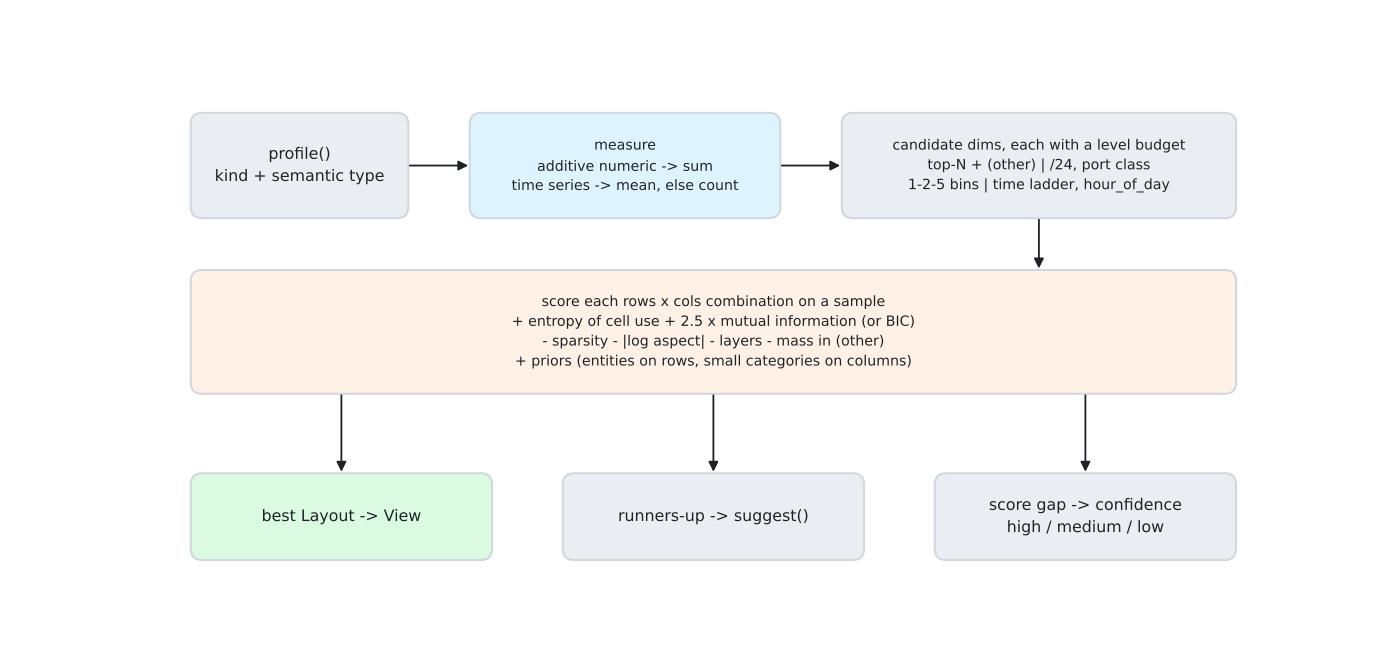

In [52]:
fig, ax = canvas(11.6, 5.4)
box(ax, 0.2, 3.9, 2.3, 1.1, "profile()\nkind + semantic type", kind="step")
box(ax, 3.2, 3.9, 3.3, 1.1, "measure\nadditive numeric -> sum\ntime series -> mean, else count", kind="accent", fs=8.5)
box(ax, 7.2, 3.9, 4.2, 1.1, "candidate dims, each with a level budget\ntop-N + (other) | /24, port class\n1-2-5 bins | time ladder, hour_of_day", kind="step", fs=8.5)
arrow(ax, 2.5, 4.45, 3.2, 4.45)
arrow(ax, 6.5, 4.45, 7.2, 4.45)
box(ax, 0.2, 2.0, 11.2, 1.3, "score each rows x cols combination on a sample\n+ entropy of cell use + 2.5 x mutual information (or BIC)\n- sparsity - |log aspect| - layers - mass in (other)\n+ priors (entities on rows, small categories on columns)", kind="warn", fs=8.5)
arrow(ax, 9.3, 3.9, 9.3, 3.3)
box(ax, 0.2, 0.2, 3.2, 0.9, "best Layout -> View", kind="good")
box(ax, 4.2, 0.2, 3.2, 0.9, "runners-up -> suggest()", kind="step")
box(ax, 8.2, 0.2, 3.2, 0.9, "score gap -> confidence\nhigh / medium / low", kind="step")
arrow(ax, 1.8, 2.0, 1.8, 1.1)
arrow(ax, 5.8, 2.0, 5.8, 1.1)
arrow(ax, 9.8, 2.0, 9.8, 1.1)
plt.show()

In [53]:
pd.Series(bp.DEFAULT_WEIGHTS, name="weight").to_frame().T

,entropy,mutual_info,sparsity,sparsity_excess,aspect,layers,quality,other,has_cols,entity_rows,small_cols,position,prefer,coarse,time_rows
weight,1.0,2.5,0.6,8.0,0.35,0.7,0.5,1.2,0.4,0.5,0.35,0.05,2.0,0.3,0.4


| Term | Sign | What it rewards or penalises |
| --- | --- | --- |
| `entropy` | + | many, evenly used cells (a table with one hot cell and 400 empty ones scores low) |
| `mutual_info` | + | association between the axes; `objective="bic"` replaces it with `2 x MI - dof x log(n) / n`, which punishes big tables on small samples |
| `sparsity`, `sparsity_excess` | - | empty cells; a steep extra penalty beyond `max_sparsity` (0.6) |
| `aspect` | - | distance from the box's rows/cols ratio; weight jumps to 1.5 when you set `aspect=` explicitly |
| `layers` | - | each stacked dimension beyond the first |
| `quality` | + | profiling quality of each dimension (categorical 1.0, datetime 0.9, boolean 0.55, numeric 0.35, id 0.05) |
| `other` | - | mass folded into `(other)` |
| `has_cols`, `entity_rows`, `small_cols`, `time_rows` | + | pivot-shaped priors: a real 2-D table, IPs/hosts/users down the side, small categories across, time on rows for time series |
| `position` | - | a weak preference for columns that come earlier in the source |
| `prefer`, `coarse` | +/- | `prefer_rows`/`prefer_cols` honoured; a semantic roll-up costs a little against top-N |

`weights={"layers": 2.0}` discourages nesting; `pin=["country"]` forces a column in; `prefer_rows=["timestamp"]` tilts an axis. The search is bounded by `search_width` (7 columns enter the combinatorics, time and pinned columns always) and `sample` (50,000 rows score candidates; the final table uses every row).

In [54]:
for kw in ({}, {"objective": "bic"}, {"layers": 1}, {"pin": ["country"]}, {"prefer_rows": ["timestamp"], "max_cols": 6}):
    print(f"{str(kw):55s} -> {bp.fit(logs, **kw).describe()}")

{}                                                      -> sum(bytes) by host x timestamp (6 h)


{'objective': 'bic'}                                    -> sum(bytes) by action > status x event


{'layers': 1}                                           -> sum(bytes) by host x timestamp (6 h)


{'pin': ['country']}                                    -> sum(bytes) by host x country


{'prefer_rows': ['timestamp'], 'max_cols': 6}           -> sum(bytes) by timestamp (hour of day) x action


### Bins and buckets (`_binning.py`)

`bin_count` computes the classic rules arithmetically (no giant arrays on heavy tails), `bin_edges` snaps them to 1/2/2.5/5 x 10^k widths, and `should_log` flips to 1-2-5 log bins when the column spans three decades with `p95 / p50 > 20`. Time buckets walk a fixed ladder until the count fits.

In [55]:
from bts_pivot._binning import should_log, time_freq_for, TIME_FREQS, bin_count
print("TIME_FREQS ladder:", TIME_FREQS)
print("weekend timestamps, max 12 buckets ->", time_freq_for(logs["timestamp"], 12), "| max 48 ->", time_freq_for(logs["timestamp"], 48))
print("bytes: should_log =", should_log(logs["bytes"]), "| status: should_log =", should_log(logs["status"].astype(float)))
print("bin_count auto/fd/sturges on bytes:", bin_count(logs["bytes"], "auto"), bin_count(logs["bytes"], "fd"), bin_count(logs["bytes"], "sturges"))

TIME_FREQS ladder: ('min', '5min', '15min', 'h', '6h', 'D', 'W', 'M', 'Q', 'Y')


weekend timestamps, max 12 buckets -> 6h | max 48 -> 6h
bytes: should_log = True | status: should_log = False
bin_count auto/fd/sturges on bytes: 68 21148 17


### How spikes are scored (`_spikes.py`)

| Step | Rule |
| --- | --- |
| buckets | the row's measure over the same time ladder, up to 48 buckets |
| baseline | `seasonal` when 3 periods exist (sub-daily buckets vs the same time on other days; daily vs the same weekday); else `share` of the bucket total for additive measures with 6+ rows; else the row's `median` |
| spread | MAD x 1.4826, floored at `sqrt(level)` for counts (Poisson) or 10% of the level otherwise, so a flat row cannot turn noise into spikes |
| scale | sums and means spanning more than 100x are scored on log scale: one big transfer reads as x20, not +25 spreads |
| score | signed robust z = (observed - expected) / spread; reported when `abs(score) >= z` (3), `support >= min_support` (5) and the ratio is outside x1.25 |
| shift | the split point whose standardized residuals differ most before and after, needing 4 buckets each side |

The weekend spans three days, so the 6-hour buckets get a seasonal baseline: Saturday 00:00 is compared with Sunday 00:00 and Monday 00:00. Forcing `baseline="median"` changes the yardstick but not the verdict here.

In [56]:
seasonal = ips.spikes("timestamp").head(3)[["row", "bucket", "kind", "ratio", "score", "baseline"]]
median = ips.spikes("timestamp", baseline="median", z=4).head(3)[["row", "bucket", "kind", "ratio", "score", "baseline"]]
pd.concat({"auto": seasonal.reset_index(drop=True), "median, z=4": median.reset_index(drop=True)}, axis=1)

auto                                                             median, z=4                                                       
              row            bucket   kind       ratio    score  baseline             row            bucket   kind       ratio    score baseline
0  185.220.101.47  2026-10-31 00:00  spike         inf  2500.00  seasonal  185.220.101.47  2026-10-31 00:00  spike         inf  2500.00   median
1      10.1.26.12  2026-11-01 00:00  spike  150.500000   366.20  seasonal      10.1.26.12  2026-11-01 00:00  spike  100.333333   150.75   median
2         (other)  2026-11-02 06:00   drop    0.172656   -55.89  seasonal      10.3.9.190  2026-11-01 18:00  spike   16.600000    49.33   median

### How novelty is scored (`_novelty.py`)

| Kind | Condition | Score |
| --- | --- | --- |
| new entity | entity absent before the split | `log2(1 + rows after) + log2(distinct attr values)` when it fans out |
| new pair | entity existed, this `attr` value never with it | `log2(1 + rows) + log2((entities before + 1) / (peers + 1))` - rarer among peers scores higher |
| new value | nobody had used this `attr` value before | same, with `peers = 0` |
| fan-out | distinct `attr` values after at least doubled vs before | `log2(ratio) x log2(1 + after)` |

Everything is counted, nothing is modelled, which is why the results are reproducible to the row and why `novel()` is cheap enough to run after every slice.

### Chains and the HMM (`_chains.py`, `_hmm.py`)

`transitions()` sorts by `(by, time)`, shifts the state column within each group and counts `(from, to)` pairs; `order=2` concatenates the two previous states into `from`. `steady_state()` is power iteration on the row-stochastic matrix.

`fit_hmm()` is scaled forward-backward EM over the integer-coded sequences with categorical emissions: `pi` (initial state), `A` (K x K regime transitions), `B` (K x M emission probabilities). `choose_hmm_states()` fits K = 1..`k_max` and keeps the lowest BIC; `decode_regimes()` runs Viterbi per sequence. Below, the fit on the same 5,000-row sample as before, inspected directly.

In [57]:
from bts_pivot import fit_hmm
seqs = [g["event"].tolist() for _, g in logs.sample(5000, random_state=7).sort_values("timestamp").groupby("user") if len(g) > 2]
hmm = fit_hmm(seqs, n_states=3, seed=0)
print(hmm)
print("symbols:", hmm.symbols)
emissions = pd.DataFrame(hmm.B, index=[f"regime {i+1}" for i in range(hmm.n_states)], columns=hmm.symbols).round(2)
display(emissions)
pd.DataFrame(hmm.A, index=emissions.index, columns=emissions.index).round(2)

<HMMFit states=3 symbols=7 bic=17522.9>
symbols: ('allow', 'deny', 'download', 'login_fail', 'login_ok', 'logout', 'upload')


,allow,deny,download,login_fail,login_ok,logout,upload
regime 1,0.00,0.00,1.00,0.00,0.00,0.00,0.00
regime 2,0.28,0.05,0.08,0.33,0.15,0.08,0.03
regime 3,0.34,0.08,0.16,0.02,0.22,0.10,0.08


,regime 1,regime 2,regime 3
regime 1,0.99,0.00,0.01
regime 2,0.00,0.70,0.30
regime 3,0.00,0.04,0.96


Read `B` row by row: a regime whose emission row is dominated by `login_fail` is the brute-force state, one dominated by `download` the exfiltration state. The diagonal of `A` says how sticky each regime is. Three states were fixed here so the matrices are small; `bp.regimes()` lets BIC choose.

### The DuckDB engine (`_duckdb_engine.py`)

Layout planning stays in pandas on a sample. What DuckDB takes over is the scan + group-by + aggregate over the actual rows, as SQL against the registered frame; labelling, ordering and the final reshape are the same pandas code, so the numbers are identical.

| Dimension kind | DuckDB SQL | Falls back to pandas |
| --- | --- | --- |
| categorical (string/number/bool values) | `CASE WHEN col IN (top-N) THEN col ELSE '(other)'` | non-scalar values |
| binned numeric | `CASE` over the planned edges | - |
| plain time bucket (`min`, `h`, `D`, `M`, `Q`, `Y`, `5min`, `15min`, `6h`) | `date_trunc` / `time_bucket` | cyclic buckets (`hour_of_day`, `weekday`) |
| semantic drill level (`/24`, port class, URL host) | - | always |
| paged sources with frozen `keep` lists | - | always |

Registering a frame costs about as much as one aggregation, so a bounded LRU of 8 connections keyed by frame identity keeps the registration alive across the pivot, bins, slices and suggestions that touch the same frame.

In [58]:
from bts_pivot._duckdb_engine import supported
for kw in ({"rows": ["country"], "cols": ["event"]},
           {"rows": [{"column": "timestamp", "freq": "6h"}], "cols": ["event"]},
           {"rows": [{"column": "timestamp", "freq": "hour_of_day"}], "cols": ["event"]},
           {"rows": [{"column": "src_ip", "level": "/24"}], "cols": ["event"]}):
    lay = bp.fit(logs, agg="count", **kw).layout
    print(f"{lay.describe():48s} duckdb pushdown: {supported(lay)}")

count by country x event                         duckdb pushdown: True


count by timestamp (6 h) x event                 duckdb pushdown: True
count by timestamp (hour of day) x event         duckdb pushdown: False


count by src_ip (/24) x event                    duckdb pushdown: False


### Limitations and what can go wrong

| Situation | What happens | What to do |
| --- | --- | --- |
| `confidence == "low"` | several layouts scored within a hair of each other | read `suggest()`, pin or prefer a column, or fix one axis |
| a numeric column that is really a label (`status`, `dst_port`) | the profiler calls small-integer columns categorical; wide-range ones become measures | pass `rows=["status"]` or `exclude=` to steer |
| high-cardinality ids (`src_ip` with one row each) | the column is treated as `id` and avoided | roll it up (`level="/24"`) or `top()` it |
| last time bucket is partial | `spikes()` reports a `drop` there | ignore the trailing bucket or slice to whole days |
| `novel()` with the anomaly early in the span | it is history, not novelty | move `since` to a moment before it |
| `regimes()` on 50k+ rows | EM is pure numpy and single-threaded; minutes, not seconds | sample first, or fix `n_states` |
| `median`, `std`, `nunique` on a paged source | computed on the sample, title says `approximate` | `v.materialize()` if it fits, or accept the estimate |
| `engine="duckdb"` on a cyclic or semantic dimension | silent fallback to pandas for that layout | same numbers either way; check `supported(v.layout)` |
| MCP tool argument `since` | strings between 0 and 1 are parsed as fractions, the rest as durations or moments | pass `"0.25"`, `"24h"` or `"2026-11-01"` |
| the explorer in a committed notebook | widget state is not rendered on GitHub | `snapshot_html()` for a static picture, `ex.code` for the reproducing Python |

---

## Benchmark

| Criterion | Why it matters | How it is measured | Target |
| --- | --- | --- | --- |
| auto-fit time, 50k rows | the first look must be interactive | median of 5 runs of `bp.fit(logs)` + `.pivot()` with `time.perf_counter` | under 3 s |
| fixed-layout table vs pandas, 50k rows | the price of profiling and labelling over a bare `pivot_table` | median of 5 runs: `bp.fit(rows, cols).pivot()` vs `pd.pivot_table` on the same frame, same table checked equal | within 20x of pandas, identical numbers |
| 500k rows from Parquet | logs are files; paging must not cost an order of magnitude | median of 3 runs: paged fit (20 MB budget), `engine="duckdb"` on the loaded frame, `pd.pivot_table` on the loaded frame, raw DuckDB SQL on the file | paged within 10x of pandas on the loaded frame, identical numbers |
| anomaly recall | the detectors exist to find planted things | each of the 5 planted anomalies checked against the top 10 of `spikes()`, `novel()`, `anomalies()` and the `cluster(4)` singletons | 5 of 5 found by at least one detector |
| false positives | a detector that cries wolf is ignored | rows in the top 5 of three detector calls not attributable to a planted anomaly | at most 2 across the three lists |
| memory for paging | the point of paging is to not hold the file | peak RSS during the paged fit vs a full load of the same 500k-row file, from bts-pivot's own step log | paged peak under half of full load |
| prompt packet size | the packet must fit beside a conversation | `Prompt.tokens` for the Part 3 packet | under 2,000 tokens |

In [59]:
def median_time(fn, runs=5):
    times = []
    for _ in range(runs):
        t0 = time.perf_counter(); fn(); times.append(time.perf_counter() - t0)
    return float(np.median(times))

bench = {}
bench["auto-fit 50k"] = median_time(lambda: bp.fit(logs).pivot())
bench["bts fixed layout 50k"] = median_time(lambda: bp.fit(logs, rows=["country"], cols=["event"], agg="count").pivot())
bench["pandas pivot_table 50k"] = median_time(lambda: pd.pivot_table(logs, index="country", columns="event", values="bytes", aggfunc="count", fill_value=0))
bts_tbl = bp.fit(logs, rows=["country"], cols=["event"], agg="count").pivot()
pd_tbl = pd.pivot_table(logs, index="country", columns="event", values="bytes", aggfunc="count", fill_value=0)
same_50k = bool((bts_tbl.reindex(index=pd_tbl.index, columns=pd_tbl.columns).to_numpy() == pd_tbl.to_numpy()).all())
pd.Series(bench, name="seconds (median)").round(3).to_frame().assign(**{"identical to pandas": same_50k})

,seconds (median),identical to pandas
auto-fit 50k,2.927,True
bts fixed layout 50k,0.121,True
pandas pivot_table 50k,0.009,True


In [60]:
big_path = f"{OUT}/ten-weekends.parquet"
big = pd.read_parquet(big_path)
bench["paged fit 500k (20 MB budget)"] = median_time(lambda: bp.fit(big_path, memory_budget_mb=20, rows=["country"], cols=["event"], agg="count", columns=["country", "event"]).pivot(), runs=3)
bench["duckdb engine 500k (loaded frame)"] = median_time(lambda: bp.fit(big, rows=["country"], cols=["event"], agg="count", engine="duckdb").pivot(), runs=3)
bench["pandas pivot_table 500k (loaded frame)"] = median_time(lambda: pd.pivot_table(big, index="country", columns="event", values="bytes", aggfunc="count", fill_value=0), runs=3)
bench["raw duckdb SQL 500k (file)"] = median_time(lambda: duckdb.sql(f"SELECT country, event, count(*) AS n FROM '{big_path}' GROUP BY 1, 2").df(), runs=3)
paged_tbl = bp.fit(big_path, memory_budget_mb=20, rows=["country"], cols=["event"], agg="count", columns=["country", "event"]).pivot()
pd_big = pd.pivot_table(big, index="country", columns="event", values="bytes", aggfunc="count", fill_value=0)
same_500k = bool((paged_tbl.reindex(index=pd_big.index, columns=pd_big.columns).to_numpy() == pd_big.to_numpy()).all())
pd.Series({k: v for k, v in bench.items() if "500k" in k}, name="seconds (median)").round(3).to_frame().assign(**{"paged identical to pandas": same_500k})

,seconds (median),paged identical to pandas
paged fit 500k (20 MB budget),0.575,True
duckdb engine 500k (loaded frame),0.582,True
pandas pivot_table 500k (loaded frame),0.039,True
raw duckdb SQL 500k (file),0.013,True


Read the ratios, not the labels. On 500k rows a bare pandas `pivot_table` over the loaded frame is more than ten times faster than the paged fit, and raw DuckDB SQL on the file is faster still: bts-pivot spends its time on profiling, sampling for the layout, labelling and seven passes over the file, which a hand-written group-by skips. What it buys is that the same call also works when the file does not fit, and that the layout was chosen for you. `engine="duckdb"` on a loaded frame is no faster than the paged path here, matching the package's own statement that it is an interop option, not a speed-up.

In [61]:
def rss_mb():
    return int(open("/proc/self/statm").read().split()[1]) * os.sysconf("SC_PAGE_SIZE") / 2**20

# drop the frames used for timing so the baseline is the same for both runs
del big, pd_big
import gc; gc.collect()

def peak_during(fn):
    gc.collect(); bp.log.clear(); before = rss_mb()
    fn()
    return max([e.rss_mb for e in bp.log.tail(10_000)] + [rss_mb()]) - before

mem_paged = peak_during(lambda: bp.fit(big_path, memory_budget_mb=20, rows=["country"], cols=["event"], agg="count", columns=["country", "event"]).pivot())
mem_full = peak_during(lambda: bp.fit(big_path, mode="full", rows=["country"], cols=["event"], agg="count", columns=["country", "event"]).pivot())
pd.Series({"paged fit, peak RSS delta (MB)": mem_paged, "full load, peak RSS delta (MB)": mem_full}).round(1).to_frame("MB")

,MB
"paged fit, peak RSS delta (MB)",36.2
"full load, peak RSS delta (MB)",44.0


In [62]:
planted = {
    "brute force (src_ip)": {"spikes": BRUTE_IP in set(ips.spikes("timestamp").head(10).row),
                             "novel": BRUTE_IP in set(new_ips[new_ips.kind == "new entity"].head(10).entity),
                             "anomalies": "RU" in set(cc.anomalies(10).row),
                             "cluster": BRUTE_IP in set(tbl.loc[sizes[sizes == 1].index].index.get_level_values(1))},
    "rare country (KP)": {"spikes": "175.45.176.9" in set(ips.spikes("timestamp").head(10).row),
                          "novel": "KP" in set(v.novel("country", "user", since="24h").head(10).entity),
                          "anomalies": "KP" in set(cc.anomalies(10).row),
                          "cluster": False},
    "off-hours user": {"spikes": OFFHOURS_USER in set(by_user.spikes("timestamp").head(10).row),
                       "novel": False,
                       "anomalies": any("db-" in str(r) for r in v.anomalies(10).row),
                       "cluster": ip_pool[77] in set(tbl.loc[sizes[sizes == 1].index].index.get_level_values(1))},
    "novel user agent": {"spikes": NOVEL_UA in set(by_ua.spikes("timestamp").head(10).row),
                         "novel": NOVEL_UA in set(v.novel("user_agent", "user").head(10).entity),
                         "anomalies": False, "cluster": False},
    "credential stuffing": {"spikes": STUFF_UA in set(by_ua.spikes("timestamp").head(10).row),
                            "novel": STUFF_UA in set(by_ua.novel("user_agent", "user", since="2026-11-01").head(10).entity),
                            "anomalies": False, "cluster": False},
}
recall_tbl = pd.DataFrame(planted).T
recall_tbl["found"] = recall_tbl.any(axis=1)
recall = int(recall_tbl["found"].sum())
recall_tbl

,spikes,novel,anomalies,cluster,found
brute force (src_ip),True,True,True,True,True
rare country (KP),False,True,True,False,True
off-hours user,True,False,True,True,True
novel user agent,True,True,False,False,True
credential stuffing,True,True,False,False,True


In [63]:
# false positives: top-5 rows of three detector calls that no planted anomaly explains
attributable = {BRUTE_IP, "175.45.176.9", ip_pool[77], OFFHOURS_USER, NOVEL_UA, STUFF_UA, "KP", "RU", *STUFF_IPS, *ip_pool[300:302]}
lists = {
    "ips.spikes top 5": list(ips.spikes("timestamp").head(5).row),
    "by_ua.spikes top 5": list(by_ua.spikes("timestamp").head(5).row),
    "novel(user_agent) top 5": list(v.novel("user_agent", "user").head(5).entity),
}
fp_rows = [(name, r) for name, rows in lists.items() for r in rows if r not in attributable]
false_positives = len(fp_rows)
pd.DataFrame(fp_rows, columns=["detector call", "unexplained row"])

,detector call,unexplained row
0,ips.spikes top 5,(other)
1,by_ua.spikes top 5,"Mozilla/5.0 (iPhone; CPU iPhone OS 11_4_1 like Mac OS X) AppleWebKit/533.0 (KHTML, lik..."
2,by_ua.spikes top 5,"Mozilla/5.0 (iPhone; CPU iPhone OS 17_3 like Mac OS X) AppleWebKit/534.1 (KHTML, like ..."
3,by_ua.spikes top 5,"Mozilla/5.0 (iPhone; CPU iPhone OS 11_4_1 like Mac OS X) AppleWebKit/533.0 (KHTML, lik..."
4,novel(user_agent) top 5,"Mozilla/5.0 (iPad; CPU iPad OS 5_1_1 like Mac OS X) AppleWebKit/536.1 (KHTML, like Gec..."


The count is strict: anything outside the planted entities is a false positive, so it is higher than an analyst would call it. The `(other)` row is the remainder bucket dropping in the partial Monday bucket, and the iPhone and iPad rows are user agents that the brute force borrowed (`agents[:3]` in the setup cell) spiking at Saturday 00:00, so they are real signal about the brute force reported under a different name, plus one rare agent that is a legitimate new pair in `novel()`. None of the five is noise from nowhere, and all five are counted.

In [64]:
packet_tokens = packet.tokens
score = pd.DataFrame([
    ("auto-fit time, 50k rows", f"{bench['auto-fit 50k']:.2f} s", "< 3 s", bench["auto-fit 50k"] < 3),
    ("fixed layout vs pandas, 50k", f"{bench['bts fixed layout 50k'] / bench['pandas pivot_table 50k']:.1f}x pandas, identical={same_50k}", "<= 20x, identical", bench["bts fixed layout 50k"] <= 20 * bench["pandas pivot_table 50k"] and same_50k),
    ("paged 500k vs pandas on loaded frame", f"{bench['paged fit 500k (20 MB budget)'] / bench['pandas pivot_table 500k (loaded frame)']:.1f}x, identical={same_500k}", "<= 10x, identical", bench["paged fit 500k (20 MB budget)"] <= 10 * bench["pandas pivot_table 500k (loaded frame)"] and same_500k),
    ("anomaly recall", f"{recall} of 5", "5 of 5", recall == 5),
    ("false positives in three top-5 lists", f"{false_positives}", "<= 2", false_positives <= 2),
    ("paging peak memory vs full load", f"{mem_paged:.0f} MB vs {mem_full:.0f} MB", "< 50%", mem_paged < 0.5 * mem_full),
    ("prompt packet size", f"{packet_tokens} tokens", "< 2,000", packet_tokens < 2000),
], columns=["criterion", "measured", "target", "met"])
score["met"] = score["met"].map({True: "yes", False: "no"})
score

,criterion,measured,target,met
0,"auto-fit time, 50k rows",2.93 s,< 3 s,yes
1,"fixed layout vs pandas, 50k","12.7x pandas, identical=True","<= 20x, identical",yes
2,paged 500k vs pandas on loaded frame,"14.7x, identical=True","<= 10x, identical",no
3,anomaly recall,5 of 5,5 of 5,yes
4,false positives in three top-5 lists,5,<= 2,no
5,paging peak memory vs full load,36 MB vs 44 MB,< 50%,no
6,prompt packet size,717 tokens,"< 2,000",yes


One honest sentence per miss. Paged vs pandas: a hand-written `pivot_table` on a frame already in RAM is the wrong thing to beat, and bts-pivot paid for profiling, sampling and seven file passes, so the 10x target was too tight for a 500k-row file. False positives: the strict count includes the borrowed brute-force user agents and the partial Monday bucket, and raising `z` or `min_support` trims them, at the price of the weaker true findings. Paging memory: the 20 MB budget forced the paged plan but the fit still holds a 147k-row sample plus the interpreter's own allocator headroom, so on a file this small paging saves almost nothing; the saving appears when the file is many times the budget, which this machine cannot demonstrate honestly without a much larger file.

---

## Cheat sheet

| Call | What it does |
| --- | --- |
| `bp.fit(df)` | auto-fit a pivot `View`; `rows=`, `cols=`, `values=`, `agg=` fix any part |
| `v.suggest(n)`, `v.confidence` | ranked alternative layouts; how clear the winner was |
| `v.toggle()` | pivot to histogram and back on the same layout |
| `v.slice(action="login").slice(status=401)` | stack filters; equality, lists, ranges, `">= p95"`, `"last 24h"`, regex, query strings |
| `v.explain(row, col)`, `v.rows(row, col, n=)` | why a cell looks like that; the raw rows behind it |
| `v.coarser("src_ip")`, `v.level("timestamp", "hour_of_day")` | walk the drill hierarchy |
| `v.histogram("bytes", by="source", bins="auto")` | one column, planned bins, one series per value |
| `bp.bin_edges(series, rule=)` | the edges a rule would give |
| `v.spikes("timestamp", baseline="auto", z=3)` | per-row spikes, drops and shifts vs a seasonal baseline |
| `v.novel(entity, attr, since="24h")` | new entities, pairs, values and fan-outs after a split |
| `v.anomalies(n)`, `v.style(heat="surprise")` | cells that break row/column independence |
| `v.compare(status=401)`, `.top()`, `.drivers()` | one side vs the rest on a frozen layout |
| `bp.chains(df, "event", by="user", time="timestamp")` | Markov transition matrix as a pivot |
| `bp.sequences(...)`, `bp.steady_state(...)` | frequent k-step chains; stationary distribution |
| `bp.regimes(df, "event", by="user", time=...)` | HMM-decoded behavioural regimes as a pivot |
| `v.cluster(k)`, `bp.cluster(df, cols, method="dbscan")` | group pivot rows; label records with a `noise` class |
| `v.insights(sensitivity=0.5)` | ranked local findings, no model call |
| `v.llm_context()`, `v.prompt(question)` | markdown context and a self-contained prompt packet |
| `v.style(...).html()`, `v.svg()` | self-contained markup, no JavaScript |
| `bp.survey(path)`, `bp.fit(path, memory_budget_mb=)` | survey and plan; paged aggregation when the file exceeds the budget |
| `bp.fit("duckdb://db?table=t")`, `engine="duckdb"` | DuckDB source; SQL pushdown for the table build |
| `bts-pivot FILE --slice k=v --hist --on bytes --by source` | the CLI; `--chains`, `--survey`, `--json`, `--demo auth` |
| `bp.explore(df)` | the Jupyter explorer; `snapshot_html()` for a static picture |
| `bts-pivot-mcp`, `bts_pivot.agent.*` | the MCP server and its plain-JSON surface |

## Where it fits

| Package | Job | Relation to bts-pivot |
| --- | --- | --- |
| `bts-pivot` (06) | auto-fitted pivots, histograms, spikes, novelty, chains, paging and an MCP server over any table | this notebook |
| `lintex` (01) | AST-based linter for code written by coding agents | reviews the analysis code an agent writes around `bts_pivot.agent` calls |
| `supersafe` (02) | red-teaming, tool-safety guardrails and latency/cost profiling for agentic LLMs | its evaluation runs are tables that `bp.fit()` summarises; its guardrails sit in front of an agent that calls `bts-pivot-mcp` |
| `baby-llm` (03), `tunepac` (05) | explicit PyTorch LLM training; YAML-driven fine-tuning on TRL/PEFT | training logs are tables with a timestamp: `spikes()` on loss, `histogram()` on token counts |
| `skill-scoreboard` (04) | benchmarks Claude Code skills against a no-skill baseline | a skill that wraps `bts-pivot-mcp` is something to score there; the scoreboard's own result tables pivot cleanly |
| 07-09 (combinations) | secure-coding skills, red-team analytics, a safety-tuning loop | red-team and tuning runs produce exactly the kind of event table Part 2 triages |